In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#internal validation

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
combined: n=11 (5 exposed / 6 control)

--- hub genes ---
Gene Set  Cohens_d     p  Power  N_for_80pct   FDR
WNT6 hub     1.211 0.070  0.431         12.0 0.102
FZD9 hub     0.722 0.298  0.187         32.0 0.341
DKK4 hub    -0.134 0.830  0.055        879.0 0.830
FZD6 hub     0.414 0.519  0.094         93.0 0.554
FZD3 hub     0.754 0.247  0.200         29.0 0.304

hub-panel LOOCV AUC = 0.667  (permutation P = 0.201)


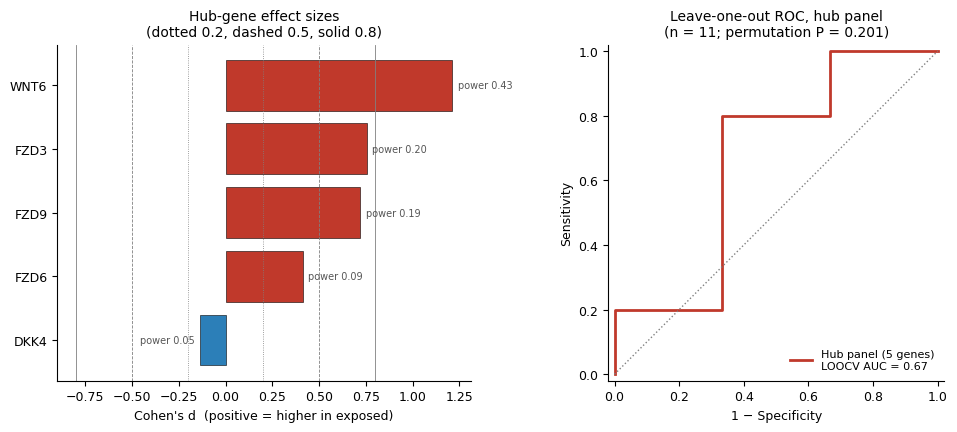


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/HubGene_Internal/


In [16]:
# ===== FIGURE: hub-gene internal assessment (replaces the 42/8/6/44 panel) =====
from google.colab import drive; drive.mount('/content/drive')
import subprocess; subprocess.run("pip install -q statsmodels scikit-learn", shell=True)
import os, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score, roc_curve

ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
DATA = ROOT + "Datasets/"
OUT  = ROOT + "Final/HubGene_Internal/"
FIG, TAB = OUT+"Figures/", OUT+"Tables/"
if os.path.isdir(OUT): shutil.rmtree(OUT)
for d in (OUT, FIG, TAB): os.makedirs(d, exist_ok=True)

HUB   = ["WNT6","FZD9","DKK4","FZD6","FZD3"]
PANEL = ["GULP1","GATAD2A","ACSS1","LOC100506530","CNTN4","LINC00485",
         "WNT6","LOC101928461","IL20RA","VWC2","RNF128","TTC6"]
LAB_D = {"GSM359332":0,"GSM359753":0,"GSM359754":0,"GSM359755":0,
         "GSM359758":1,"GSM359759":1,"GSM359760":1}
LAB_V = {"GSM305784":0,"GSM305785":0,"GSM305786":1,"GSM305787":1}
ALPHA, SEED = 0.05, 42
np.random.seed(SEED)
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

def load(path, labels):
    E = pd.read_csv(path, index_col=0).apply(pd.to_numeric, errors="coerce")
    E = E[E.notna().all(axis=1)]
    if float(np.nanmax(E.values)) > 50: E = np.log2(E.clip(lower=0)+1)
    s = [c for c in E.columns if c in labels]; E = E[s]
    E = E.sub(E.mean(axis=1), axis=0).div(E.std(axis=1, ddof=0).replace(0,1), axis=0)
    return E, np.array([labels[c] for c in s])

A, yA = load(DATA+"GSE14390_gene_expression.csv", LAB_D)
B, yB = load(DATA+"GSE12131_gene_expression.csv", LAB_V)
shared = sorted(set(A.index) & set(B.index))
M = pd.concat([A.loc[shared], B.loc[shared]], axis=1).T
y = np.concatenate([yA, yB])
origin = np.array(["GSE14390"]*len(yA) + ["GSE12131"]*len(yB))
print(f"combined: n={len(y)} ({y.sum()} exposed / {(1-y).sum()} control)")

pa = TTestIndPower(); rows = []
for g in HUB + [x for x in PANEL if x not in HUB]:
    if g not in M.columns: continue
    a, c = M.loc[y==1, g], M.loc[y==0, g]
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(c)-1)*c.var(ddof=1))/(len(a)+len(c)-2))
    d = (a.mean()-c.mean())/sp if sp > 0 else 0.0
    p = stats.ttest_ind(a, c, equal_var=False).pvalue
    try: pw = pa.solve_power(effect_size=abs(d), nobs1=len(a), ratio=len(c)/len(a),
                             alpha=ALPHA, alternative="two-sided")
    except Exception: pw = np.nan
    need = np.nan
    if 0.01 < abs(d) < 10:
        try: need = np.ceil(pa.solve_power(effect_size=abs(d), power=0.80, ratio=1.0,
                                           alpha=ALPHA, alternative="two-sided"))
        except Exception: pass
    rows.append(dict(Gene=g, Set="hub" if g in HUB else "common DEG",
                     Cohens_d=d, p=p, Power=pw, N_for_80pct=need))
T = pd.DataFrame(rows)
T["FDR"] = multipletests(T.p, method="fdr_bh")[1]
T.round(4).to_csv(TAB+"Table_hub_internal_assessment.csv", index=False)
print("\n--- hub genes ---")
print(T[T.Set=="hub"].round(3).to_string(index=False))

# leave-one-out ROC for the hub panel
hub_present = [g for g in HUB if g in M.columns]
X = M[hub_present]
prob = np.zeros(len(y))
for tr, te in LeaveOneOut().split(X):
    if len(np.unique(y[tr])) < 2: continue
    mu, sd = X.iloc[tr].mean(), X.iloc[tr].std(ddof=0).replace(0,1)
    m = LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000).fit(
        (X.iloc[tr]-mu)/sd, y[tr])
    prob[te] = m.predict_proba(((X.iloc[te]-mu)/sd).fillna(0))[:,1]
auc_hub = roc_auc_score(y, prob)
fpr, tpr, _ = roc_curve(y, prob)
perm = np.array([roc_auc_score(np.random.permutation(y), prob) for _ in range(5000)])
p_perm = (np.sum(perm >= auc_hub)+1)/5001
print(f"\nhub-panel LOOCV AUC = {auc_hub:.3f}  (permutation P = {p_perm:.3f})")
pd.DataFrame({"Sample":M.index,"Dataset":origin,
              "Group":np.where(y==1,"Exposed","Control"),"LOO_probability":prob}
             ).round(4).to_csv(TAB+"Table_hub_loo_predictions.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))
H = T[T.Set=="hub"].sort_values("Cohens_d")
ax[0].barh(H.Gene, H.Cohens_d,
           color=np.where(H.Cohens_d > 0, "#c0392b", "#2c7fb8"), edgecolor="black", lw=.4)
for x_, s_ in [(0.2,":"),(0.5,"--"),(0.8,"-")]:
    for sg in (1,-1): ax[0].axvline(sg*x_, ls=s_, c="grey", lw=.6)
ax[0].set_xlabel("Cohen's d  (positive = higher in exposed)")
ax[0].set_title("Hub-gene effect sizes\n(dotted 0.2, dashed 0.5, solid 0.8)", fontsize=10)
for i, (_, r) in enumerate(H.iterrows()):
    ax[0].text(r.Cohens_d + (0.03 if r.Cohens_d>0 else -0.03), i,
               f"power {r.Power:.2f}", va="center",
               ha="left" if r.Cohens_d>0 else "right", fontsize=7, color="#555")

ax[1].plot(fpr, tpr, color="#c0392b", lw=2,
           label=f"Hub panel (5 genes)\nLOOCV AUC = {auc_hub:.2f}")
ax[1].plot([0,1],[0,1], ":", c="grey", lw=1)
ax[1].set_xlim(-.02,1.02); ax[1].set_ylim(-.02,1.02); ax[1].set_aspect("equal")
ax[1].set_xlabel("1 − Specificity"); ax[1].set_ylabel("Sensitivity")
ax[1].set_title(f"Leave-one-out ROC, hub panel\n(n = {len(y)}; permutation P = {p_perm:.3f})",
                fontsize=10)
ax[1].legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG+"Fig5AB_hub_internal.png", dpi=600, bbox_inches="tight")
fig.savefig(FIG+"Fig5AB_hub_internal.pdf", bbox_inches="tight")
plt.show(); print("\nSaved ->", OUT)

  apparent        : AUC 0.967 | accuracy 0.909   <- optimistic
  leave-one-out   : AUC 0.667 | accuracy 0.455   <- report this
  optimism        : AUC +0.300 | accuracy +0.455
  permutation P (LOOCV AUC) = 0.200

  apparent confusion matrix (n=11):
[[5 1]
 [0 5]]

  leave-one-out confusion matrix (n=11):
[[4 2]
 [4 1]]


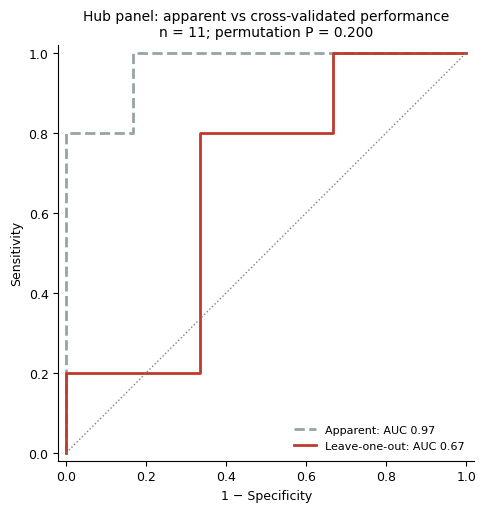


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/HubGene_Internal/


In [17]:
# ===== HUB PANEL: apparent vs cross-validated performance =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

OUT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/HubGene_Internal/"
hub_present = [g for g in HUB if g in M.columns]       # from the previous cell
X = M[hub_present]
Z = (X - X.mean())/X.std(ddof=0).replace(0,1)

# ---- apparent: fitted and scored on the same 11 samples (optimistic) ----
m_app = LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000).fit(Z, y)
p_app = m_app.predict_proba(Z)[:,1]
auc_app = roc_auc_score(y, p_app)
f_a, t_a, th_a = roc_curve(y, p_app)
thr_app = float(th_a[np.argmax(t_a - f_a)])
cm_app = confusion_matrix(y, (p_app >= thr_app).astype(int))
acc_app = np.trace(cm_app)/cm_app.sum()

# ---- cross-validated: the honest estimate ----
p_cv = np.zeros(len(y))
for tr, te in LeaveOneOut().split(Z):
    if len(np.unique(y[tr])) < 2: continue
    mu, sd = X.iloc[tr].mean(), X.iloc[tr].std(ddof=0).replace(0,1)
    mm = LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)\
         .fit((X.iloc[tr]-mu)/sd, y[tr])
    p_cv[te] = mm.predict_proba(((X.iloc[te]-mu)/sd).fillna(0))[:,1]
auc_cv = roc_auc_score(y, p_cv)
f_c, t_c, _ = roc_curve(y, p_cv)
cm_cv = confusion_matrix(y, (p_cv >= thr_app).astype(int))
acc_cv = np.trace(cm_cv)/cm_cv.sum()
perm = np.array([roc_auc_score(np.random.permutation(y), p_cv) for _ in range(5000)])
p_perm = (np.sum(perm >= auc_cv)+1)/5001

print("="*62)
print(f"  apparent        : AUC {auc_app:.3f} | accuracy {acc_app:.3f}   <- optimistic")
print(f"  leave-one-out   : AUC {auc_cv:.3f} | accuracy {acc_cv:.3f}   <- report this")
print(f"  optimism        : AUC {auc_app-auc_cv:+.3f} | accuracy {acc_app-acc_cv:+.3f}")
print(f"  permutation P (LOOCV AUC) = {p_perm:.3f}")
print("="*62)
print(f"\n  apparent confusion matrix (n={cm_app.sum()}):\n{cm_app}")
print(f"\n  leave-one-out confusion matrix (n={cm_cv.sum()}):\n{cm_cv}")

pd.DataFrame([
    dict(Estimate="Apparent (resubstitution)", AUC=auc_app, Accuracy=acc_app,
         TN=cm_app[0,0], FP=cm_app[0,1], FN=cm_app[1,0], TP=cm_app[1,1],
         Note="fitted and scored on the same samples; optimistic"),
    dict(Estimate="Leave-one-out cross-validation", AUC=auc_cv, Accuracy=acc_cv,
         TN=cm_cv[0,0], FP=cm_cv[0,1], FN=cm_cv[1,0], TP=cm_cv[1,1],
         Note=f"permutation P = {p_perm:.3f}"),
]).round(3).to_csv(OUT+"Tables/Table_hub_apparent_vs_cv.csv", index=False)

fig, ax = plt.subplots(figsize=(5.4,5.2))
ax.plot(f_a, t_a, "--", c="#95a5a6", lw=2, label=f"Apparent: AUC {auc_app:.2f}")
ax.plot(f_c, t_c, "-",  c="#c0392b", lw=2,
        label=f"Leave-one-out: AUC {auc_cv:.2f}")
ax.plot([0,1],[0,1], ":", c="grey", lw=1)
ax.set_xlim(-.02,1.02); ax.set_ylim(-.02,1.02); ax.set_aspect("equal")
ax.set_xlabel("1 − Specificity"); ax.set_ylabel("Sensitivity")
ax.set_title(f"Hub panel: apparent vs cross-validated performance\n"
             f"n = {len(y)}; permutation P = {p_perm:.3f}", fontsize=10)
ax.legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(OUT+"Figures/Fig5B_apparent_vs_cv.png", dpi=600, bbox_inches="tight")
fig.savefig(OUT+"Figures/Fig5B_apparent_vs_cv.pdf", bbox_inches="tight")
plt.show(); print("\nSaved ->", OUT)

In [18]:
# ===== TABLE: apparent vs cross-validated performance of the hub panel =====
# run after the previous hub-gene cell (needs M, y, HUB, origin)
import os, numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

OUT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/HubGene_Internal/"
TAB = OUT + "Tables/"; os.makedirs(TAB, exist_ok=True)
SEED = 42; np.random.seed(SEED)

hub_present = [g for g in HUB if g in M.columns]
X = M[hub_present]
Z = (X - X.mean()) / X.std(ddof=0).replace(0, 1)
print(f"hub panel: {len(hub_present)} genes | n = {len(y)} "
      f"({y.sum()} exposed / {(1-y).sum()} control)")

def metrics(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return dict(
        AUC=roc_auc_score(y_true, prob),
        Accuracy=(tp + tn) / cm.sum(),
        Sensitivity=tp / max(tp + fn, 1),
        Specificity=tn / max(tn + fp, 1),
        PPV=tp / max(tp + fp, 1),
        NPV=tn / max(tn + fn, 1),
        TP=int(tp), FP=int(fp), TN=int(tn), FN=int(fn))

# ---------- apparent: fitted and scored on the same samples ----------
m_app = LogisticRegression(C=0.1, class_weight="balanced",
                           max_iter=5000, random_state=SEED).fit(Z, y)
p_app = m_app.predict_proba(Z)[:, 1]
f_a, t_a, th_a = roc_curve(y, p_app)
thr = float(th_a[np.argmax(t_a - f_a)])          # Youden threshold, fixed here
app = metrics(y, p_app, thr)

# ---------- leave-one-out: refitted without each sample ----------
p_cv = np.zeros(len(y))
for tr, te in LeaveOneOut().split(Z):
    if len(np.unique(y[tr])) < 2:
        p_cv[te] = np.nan; continue
    mu, sd = X.iloc[tr].mean(), X.iloc[tr].std(ddof=0).replace(0, 1)
    mm = LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000,
                            random_state=SEED).fit((X.iloc[tr] - mu) / sd, y[tr])
    p_cv[te] = mm.predict_proba(((X.iloc[te] - mu) / sd).fillna(0))[:, 1]
cv = metrics(y, p_cv, thr)

perm = np.array([roc_auc_score(np.random.permutation(y), p_cv) for _ in range(5000)])
p_perm = (np.sum(perm >= cv["AUC"]) + 1) / 5001

# ---------- main table ----------
T = pd.DataFrame([
    dict(Estimate="Apparent (resubstitution)", **app,
         Permutation_P=np.nan,
         Interpretation="Fitted and evaluated on the same 11 samples; optimistic"),
    dict(Estimate="Leave-one-out cross-validation", **cv,
         Permutation_P=p_perm,
         Interpretation="Each sample scored by a model refitted without it"),
])
T["Optimism"] = [np.nan, round(app["AUC"] - cv["AUC"], 3)]
cols = ["Estimate", "AUC", "Accuracy", "Sensitivity", "Specificity", "PPV", "NPV",
        "TP", "FP", "TN", "FN", "Permutation_P", "Optimism", "Interpretation"]
T = T[cols]
T.round(3).to_csv(TAB + "Table2_hub_apparent_vs_cv.csv", index=False)

print("\n" + "=" * 80)
print(T.drop(columns="Interpretation").round(3).to_string(index=False))
print("=" * 80)
print(f"  threshold (Youden, apparent) = {thr:.3f}")
print(f"  optimism: AUC {app['AUC'] - cv['AUC']:+.3f} | "
      f"accuracy {app['Accuracy'] - cv['Accuracy']:+.3f}")

# ---------- per-sample predictions ----------
P = pd.DataFrame({
    "Sample": M.index, "Dataset": origin,
    "Group": np.where(y == 1, "Exposed", "Control"),
    "Apparent_probability": p_app.round(4),
    "LOO_probability": np.round(p_cv, 4),
    "Apparent_call": np.where(p_app >= thr, "Exposed", "Control"),
    "LOO_call": np.where(p_cv >= thr, "Exposed", "Control")})
P["Apparent_correct"] = P.Group == P.Apparent_call
P["LOO_correct"] = P.Group == P.LOO_call
P.to_csv(TAB + "TableS_hub_per_sample_predictions.csv", index=False)
print(f"\ncorrect calls — apparent {int(P.Apparent_correct.sum())}/{len(P)} | "
      f"LOOCV {int(P.LOO_correct.sum())}/{len(P)}")
print(P.to_string(index=False))
print(f"\nSaved -> {TAB}")

hub panel: 5 genes | n = 11 (5 exposed / 6 control)

                      Estimate   AUC  Accuracy  Sensitivity  Specificity   PPV  NPV  TP  FP  TN  FN  Permutation_P  Optimism
     Apparent (resubstitution) 0.967     0.909          1.0        0.833 0.833  1.0   5   1   5   0            NaN       NaN
Leave-one-out cross-validation 0.667     0.455          0.2        0.667 0.333  0.5   1   2   4   4          0.201       0.3
  threshold (Youden, apparent) = 0.518
  optimism: AUC +0.300 | accuracy +0.455

correct calls — apparent 10/11 | LOOCV 5/11
   Sample  Dataset   Group  Apparent_probability  LOO_probability Apparent_call LOO_call  Apparent_correct  LOO_correct
GSM359332 GSE14390 Control                0.4195           0.4496       Control  Control              True         True
GSM359753 GSE14390 Control                0.5184           0.5523       Exposed  Exposed             False        False
GSM359754 GSE14390 Control                0.3625           0.4108       Control  Contro

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA
  GSE14390: 23520 genes x 7 samples (3 exposed / 4 control) | log2=False
  GSE12131: 23520 genes x 4 samples (2 exposed / 2 control) | log2=True

  combined discovery cohort: n=11 (5 exposed / 6 control), 23520 shared genes
  hub genes present: 5/5  (WNT6, FZD9, DKK4, FZD6, FZD3)

1. PER-GENE EFFECT SIZE AND POWER
Gene  Cohens_d     Effect  t_test_p  t_test_FDR  Achieved_power  N_per_group_for_80pct
WNT6     1.211      large     0.070       0.102           0.431                   12.0
FZD3     0.754     medium     0.247       0.304           0.200                   29.0
FZD9     0.722     medium     0.298       0.341           0.187                   32.0
FZD6     0.414      small     0.519       0.554           0.094                   93.0
DKK4    -0.134 negligible     0.830       0.830           0.055                  879.0

  hub genes with power >= 0

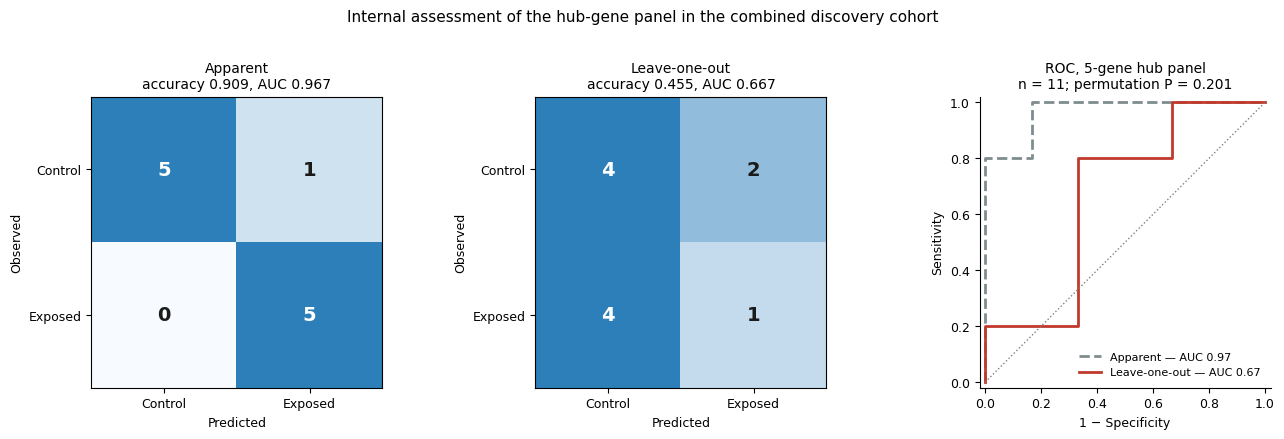

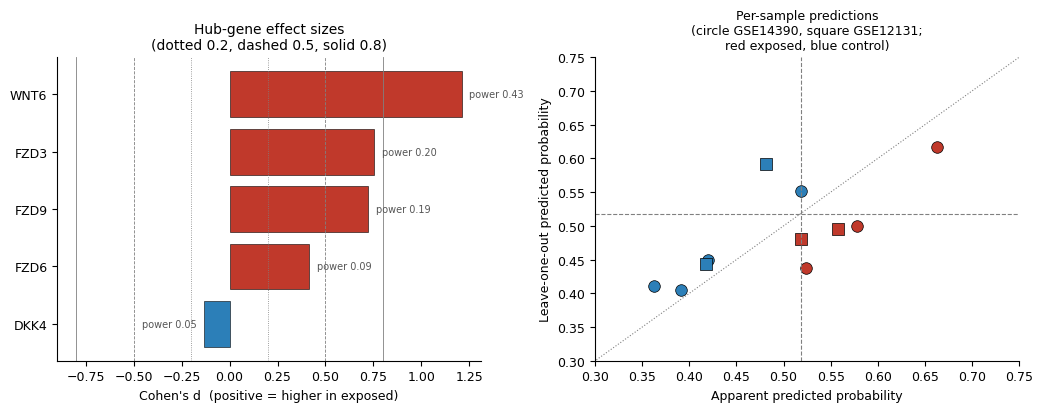


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Section36_HubGene/


In [19]:
# ===== SECTION 3.6 — HUB GENE INTERNAL VALIDATION (single cell) =====
from google.colab import drive; drive.mount('/content/drive')
import subprocess; subprocess.run("pip install -q statsmodels scikit-learn", shell=True)
import os, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

# ------------------------------- CONFIG -------------------------------
ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
DATA = ROOT + "Datasets/"
OUT  = ROOT + "Final/Section36_HubGene/"
FIG, TAB, SUP = OUT+"Figures/", OUT+"Tables/", OUT+"Supplementary/"
if os.path.isdir(OUT): shutil.rmtree(OUT)
for d in (OUT, FIG, TAB, SUP): os.makedirs(d, exist_ok=True)

HUB   = ["WNT6","FZD9","DKK4","FZD6","FZD3"]
PANEL = ["GULP1","GATAD2A","ACSS1","LOC100506530","CNTN4","LINC00485",
         "WNT6","LOC101928461","IL20RA","VWC2","RNF128","TTC6"]
SRC = {"GSE14390": (DATA+"GSE14390_gene_expression.csv",
                    {"GSM359332":0,"GSM359753":0,"GSM359754":0,"GSM359755":0,
                     "GSM359758":1,"GSM359759":1,"GSM359760":1}),
       "GSE12131": (DATA+"GSE12131_gene_expression.csv",
                    {"GSM305784":0,"GSM305785":0,"GSM305786":1,"GSM305787":1})}
ALPHA, POWER_TARGET, C_PENALTY, N_PERM, SEED = 0.05, 0.80, 0.1, 5000, 42
np.random.seed(SEED)
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

# ------------------------------- LOAD + COMBINE -------------------------------
print("="*80+"\nDATA\n"+"="*80)
frames, ys, origins = [], [], []
for name,(path,lab) in SRC.items():
    E = pd.read_csv(path, index_col=0).apply(pd.to_numeric, errors="coerce")
    E = E[E.notna().all(axis=1)]
    logged = float(np.nanmax(E.values)) > 50
    if logged: E = np.log2(E.clip(lower=0)+1)
    s = [c for c in E.columns if c in lab]; E = E[s]
    E = E.sub(E.mean(axis=1), axis=0).div(E.std(axis=1, ddof=0).replace(0,1), axis=0)
    y_ = np.array([lab[c] for c in s])
    frames.append(E); ys.append(y_); origins += [name]*len(s)
    print(f"  {name}: {E.shape[0]} genes x {len(s)} samples "
          f"({y_.sum()} exposed / {(1-y_).sum()} control) | log2={logged}")

shared = sorted(set(frames[0].index) & set(frames[1].index))
M = pd.concat([f.loc[shared] for f in frames], axis=1).T
y = np.concatenate(ys); origin = np.array(origins)
n1, n0 = int(y.sum()), int((1-y).sum())
print(f"\n  combined discovery cohort: n={len(y)} ({n1} exposed / {n0} control), "
      f"{len(shared)} shared genes")
hub = [g for g in HUB if g in M.columns]
print(f"  hub genes present: {len(hub)}/5  ({', '.join(hub)})")
pd.DataFrame({"Sample":M.index,"Dataset":origin,
              "Group":np.where(y==1,"Exposed","Control")}).to_csv(
    SUP+"TableS_sample_annotation.csv", index=False)

# =============== 1. PER-GENE EFFECT SIZE AND POWER ===============
print("\n"+"="*80+"\n1. PER-GENE EFFECT SIZE AND POWER\n"+"="*80)
pa = TTestIndPower(); rows=[]
for g in hub + [x for x in PANEL if x not in HUB and x in M.columns]:
    a, c = M.loc[y==1,g], M.loc[y==0,g]
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(c)-1)*c.var(ddof=1))/(len(a)+len(c)-2))
    d  = (a.mean()-c.mean())/sp if sp>0 else 0.0
    tp = stats.ttest_ind(a,c,equal_var=False).pvalue
    wp = stats.mannwhitneyu(a,c,alternative="two-sided").pvalue
    try: pw = pa.solve_power(effect_size=abs(d), nobs1=len(a), ratio=len(c)/len(a),
                             alpha=ALPHA, alternative="two-sided")
    except Exception: pw = np.nan
    need = np.nan
    if 0.01 < abs(d) < 10:
        try: need = np.ceil(pa.solve_power(effect_size=abs(d), power=POWER_TARGET,
                                           ratio=1.0, alpha=ALPHA,
                                           alternative="two-sided"))
        except Exception: pass
    rows.append(dict(Gene=g, Set=("hub" if g in HUB else "common DEG"),
        Mean_exposed=a.mean(), Mean_control=c.mean(), Cohens_d=d,
        Effect=("negligible" if abs(d)<.2 else "small" if abs(d)<.5 else
                "medium" if abs(d)<.8 else "large"),
        t_test_p=tp, Wilcoxon_p=wp, Achieved_power=pw,
        Adequate=("Yes" if (pw or 0)>=POWER_TARGET else "No"),
        N_per_group_for_80pct=need))
G = pd.DataFrame(rows)
G["t_test_FDR"] = multipletests(G.t_test_p, method="fdr_bh")[1]
G.round(4).to_csv(TAB+"Table1_hub_effect_size_power.csv", index=False)
H = G[G.Set=="hub"].sort_values("Cohens_d", ascending=False)
print(H[["Gene","Cohens_d","Effect","t_test_p","t_test_FDR",
         "Achieved_power","N_per_group_for_80pct"]].round(3).to_string(index=False))
print(f"\n  hub genes with power >= {POWER_TARGET}: {(H.Adequate=='Yes').sum()}/{len(H)}")
print(f"  hub genes with FDR < 0.05          : {(H.t_test_FDR<0.05).sum()}/{len(H)}")

# =============== 2. APPARENT vs LEAVE-ONE-OUT ===============
print("\n"+"="*80+"\n2. APPARENT vs LEAVE-ONE-OUT PERFORMANCE\n"+"="*80)
X = M[hub]; Z = (X - X.mean())/X.std(ddof=0).replace(0,1)

m_app = LogisticRegression(C=C_PENALTY, class_weight="balanced",
                           max_iter=5000, random_state=SEED).fit(Z, y)
p_app = m_app.predict_proba(Z)[:,1]
f_a, t_a, th_a = roc_curve(y, p_app)
THR = float(th_a[np.argmax(t_a - f_a)])

p_cv = np.zeros(len(y))
for tr, te in LeaveOneOut().split(Z):
    if len(np.unique(y[tr])) < 2: p_cv[te] = np.nan; continue
    mu, sd = X.iloc[tr].mean(), X.iloc[tr].std(ddof=0).replace(0,1)
    mm = LogisticRegression(C=C_PENALTY, class_weight="balanced", max_iter=5000,
                            random_state=SEED).fit((X.iloc[tr]-mu)/sd, y[tr])
    p_cv[te] = mm.predict_proba(((X.iloc[te]-mu)/sd).fillna(0))[:,1]
f_c, t_c, _ = roc_curve(y, p_cv)

def met(prob, thr):
    pred = (prob>=thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0,1]).ravel()
    return dict(AUC=roc_auc_score(y,prob), Accuracy=(tp+tn)/len(y),
                Sensitivity=tp/max(tp+fn,1), Specificity=tn/max(tn+fp,1),
                PPV=tp/max(tp+fp,1), NPV=tn/max(tn+fn,1),
                TP=int(tp), FP=int(fp), TN=int(tn), FN=int(fn))
app, cv = met(p_app, THR), met(p_cv, THR)
perm = np.array([roc_auc_score(np.random.permutation(y), p_cv) for _ in range(N_PERM)])
P_PERM = (np.sum(perm >= cv["AUC"])+1)/(N_PERM+1)

T2 = pd.DataFrame([
    dict(Estimate="Apparent (resubstitution)", **app, Permutation_P=np.nan,
         Note="Fitted and scored on the same samples; optimistic upper bound"),
    dict(Estimate="Leave-one-out cross-validation", **cv, Permutation_P=P_PERM,
         Note="Each sample scored by a model refitted without it")])
T2["Optimism_AUC"] = [np.nan, round(app["AUC"]-cv["AUC"],3)]
T2["Optimism_Accuracy"] = [np.nan, round(app["Accuracy"]-cv["Accuracy"],3)]
T2.round(3).to_csv(TAB+"Table2_apparent_vs_LOOCV.csv", index=False)
print(T2.drop(columns="Note").round(3).to_string(index=False))
print(f"\n  classification threshold (apparent Youden) = {THR:.3f}")
print(f"  permutation P for the cross-validated AUC   = {P_PERM:.3f}")

P = pd.DataFrame({"Sample":M.index, "Dataset":origin,
    "Group":np.where(y==1,"Exposed","Control"),
    "Apparent_probability":p_app.round(4), "LOO_probability":np.round(p_cv,4),
    "Apparent_call":np.where(p_app>=THR,"Exposed","Control"),
    "LOO_call":np.where(p_cv>=THR,"Exposed","Control")})
P["Apparent_correct"] = P.Group == P.Apparent_call
P["LOO_correct"] = P.Group == P.LOO_call
P.to_csv(SUP+"TableS_per_sample_predictions.csv", index=False)
print(f"\n  correct calls — apparent {int(P.Apparent_correct.sum())}/{len(P)} | "
      f"LOOCV {int(P.LOO_correct.sum())}/{len(P)}")
print(f"  LOOCV probability range: {np.nanmin(p_cv):.3f} – {np.nanmax(p_cv):.3f} "
      f"(threshold {THR:.3f})")

# =============== 3. FIGURES ===============
BLUE = LinearSegmentedColormap.from_list("b", ["#f7fbff", "#2c7fb8"])

def draw_cm(ax, m, title):
    im = ax.imshow(m, cmap=BLUE, vmin=0, vmax=m.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i,j], ha="center", va="center", fontsize=14,
                    fontweight="bold",
                    color="white" if m[i,j] > m.max()*0.55 else "#1a1a1a")
    ax.set_xticks([0,1]); ax.set_xticklabels(["Control","Exposed"])
    ax.set_yticks([0,1]); ax.set_yticklabels(["Control","Exposed"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Observed")
    ax.set_title(title, fontsize=10)
    for sp in ax.spines.values(): sp.set_visible(True)
    return im

cm_app = confusion_matrix(y, (p_app>=THR).astype(int), labels=[0,1])
cm_cv  = confusion_matrix(y, (p_cv>=THR).astype(int), labels=[0,1])

fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.3))
draw_cm(ax[0], cm_app, f"Apparent\naccuracy {app['Accuracy']:.3f}, AUC {app['AUC']:.3f}")
draw_cm(ax[1], cm_cv,  f"Leave-one-out\naccuracy {cv['Accuracy']:.3f}, AUC {cv['AUC']:.3f}")
ax[2].plot(f_a, t_a, "--", c="#7f8c8d", lw=2, label=f"Apparent — AUC {app['AUC']:.2f}")
ax[2].plot(f_c, t_c, "-",  c="#c0392b", lw=2,
           label=f"Leave-one-out — AUC {cv['AUC']:.2f}")
ax[2].plot([0,1],[0,1], ":", c="grey", lw=1)
ax[2].set_xlim(-.02,1.02); ax[2].set_ylim(-.02,1.02); ax[2].set_aspect("equal")
ax[2].set_xlabel("1 − Specificity"); ax[2].set_ylabel("Sensitivity")
ax[2].set_title(f"ROC, {len(hub)}-gene hub panel\n"
                f"n = {len(y)}; permutation P = {P_PERM:.3f}", fontsize=10)
ax[2].legend(loc="lower right", fontsize=8, frameon=False)
fig.suptitle("Internal assessment of the hub-gene panel in the combined discovery cohort",
             fontsize=11)
fig.tight_layout(rect=[0,0,1,.93])
fig.savefig(FIG+"Fig5_hub_internal_validation.png", dpi=600, bbox_inches="tight")
fig.savefig(FIG+"Fig5_hub_internal_validation.pdf", bbox_inches="tight")

fig2, ax = plt.subplots(1, 2, figsize=(10.5, 4.2))
Hs = H.sort_values("Cohens_d")
ax[0].barh(Hs.Gene, Hs.Cohens_d,
           color=np.where(Hs.Cohens_d>0, "#c0392b", "#2c7fb8"), edgecolor="black", lw=.4)
for x_, s_ in [(.2,":"),(.5,"--"),(.8,"-")]:
    for sg in (1,-1): ax[0].axvline(sg*x_, ls=s_, c="grey", lw=.6)
for i, (_, r) in enumerate(Hs.iterrows()):
    ax[0].text(r.Cohens_d + (.04 if r.Cohens_d>0 else -.04), i, f"power {r.Achieved_power:.2f}",
               va="center", ha="left" if r.Cohens_d>0 else "right", fontsize=7, color="#555")
ax[0].set_xlabel("Cohen's d  (positive = higher in exposed)")
ax[0].set_title("Hub-gene effect sizes\n(dotted 0.2, dashed 0.5, solid 0.8)", fontsize=10)

col = np.where(P.Group=="Exposed", "#c0392b", "#2c7fb8")
mk  = np.where(P.Dataset=="GSE14390", "o", "s")
for i in range(len(P)):
    ax[1].scatter(P.Apparent_probability[i], P.LOO_probability[i],
                  marker=mk[i], c=col[i], s=70, edgecolor="black", lw=.5)
ax[1].axhline(THR, ls="--", c="grey", lw=.8); ax[1].axvline(THR, ls="--", c="grey", lw=.8)
ax[1].plot([0,1],[0,1], ":", c="grey", lw=.8)
ax[1].set_xlim(0.3,0.75); ax[1].set_ylim(0.3,0.75)
ax[1].set_xlabel("Apparent predicted probability")
ax[1].set_ylabel("Leave-one-out predicted probability")
ax[1].set_title("Per-sample predictions\n(circle GSE14390, square GSE12131;\n"
                "red exposed, blue control)", fontsize=9)
fig2.tight_layout()
fig2.savefig(SUP+"FigS_hub_effect_and_predictions.png", dpi=600, bbox_inches="tight")
fig2.savefig(SUP+"FigS_hub_effect_and_predictions.pdf", bbox_inches="tight")

# =============== VALIDITY REPORT ===============
rep = pd.DataFrame({"Item":[
    "Cohorts combined","Samples","Exposed / Control","Hub genes","Penalty (C)",
    "Apparent AUC","Apparent accuracy","LOOCV AUC","LOOCV accuracy",
    "Optimism (AUC)","Optimism (accuracy)","Permutation P (LOOCV AUC)",
    "Hub genes with power >= 0.80","Hub genes with FDR < 0.05",
    "LOOCV probability range","Interpretation"],
  "Value":["GSE14390 + GSE12131", len(y), f"{n1} / {n0}", len(hub), C_PENALTY,
    round(app["AUC"],3), round(app["Accuracy"],3),
    round(cv["AUC"],3), round(cv["Accuracy"],3),
    round(app["AUC"]-cv["AUC"],3), round(app["Accuracy"]-cv["Accuracy"],3),
    round(P_PERM,3), int((H.Adequate=="Yes").sum()), int((H.t_test_FDR<0.05).sum()),
    f"{np.nanmin(p_cv):.3f}–{np.nanmax(p_cv):.3f}",
    "Report cross-validated values; apparent values are an optimistic upper bound"]})
rep.to_csv(SUP+"TableS_validity_report.csv", index=False)
print("\n"+"="*80+"\nVALIDITY REPORT\n"+"="*80)
print(rep.to_string(index=False))

print("\n--- OUTPUT ---")
for folder, lbl in [(FIG,"Figures"), (TAB,"Tables"), (SUP,"Supplementary")]:
    print(f"\n{lbl}:")
    for f in sorted(os.listdir(folder)): print(f"   {f}")
plt.show(); print("\nSaved ->", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA
  GSE14390: 42904 probe columns x 7 samples (3 exposed / 4 control) | log2=False
  GSE12131: 42904 probe columns x 4 samples (2 exposed / 2 control) | log2=True

  combined: n=11 (5 exposed / 6 control)
  NOTE: no significance or expression filter applied — every panel gene is kept

1. PER-GENE STATISTICS — no threshold applied
        Gene        Set  Cohens_d  raw_p  Achieved_power   FDR
LOC101928461 common DEG     2.251  0.004           0.910 0.039
   LINC00485 common DEG    -2.188  0.005           0.894 0.039
        WNT6       both     2.068  0.011           0.859 0.047
      RNF128 common DEG     2.056  0.012           0.855 0.047
LOC100506530 common DEG    -2.115  0.015           0.874 0.048
        VWC2 common DEG    -1.922  0.027           0.806 0.071
       GULP1 common DEG     1.526  0.032           0.613 0.073
       CNTN4 common DEG     1.00

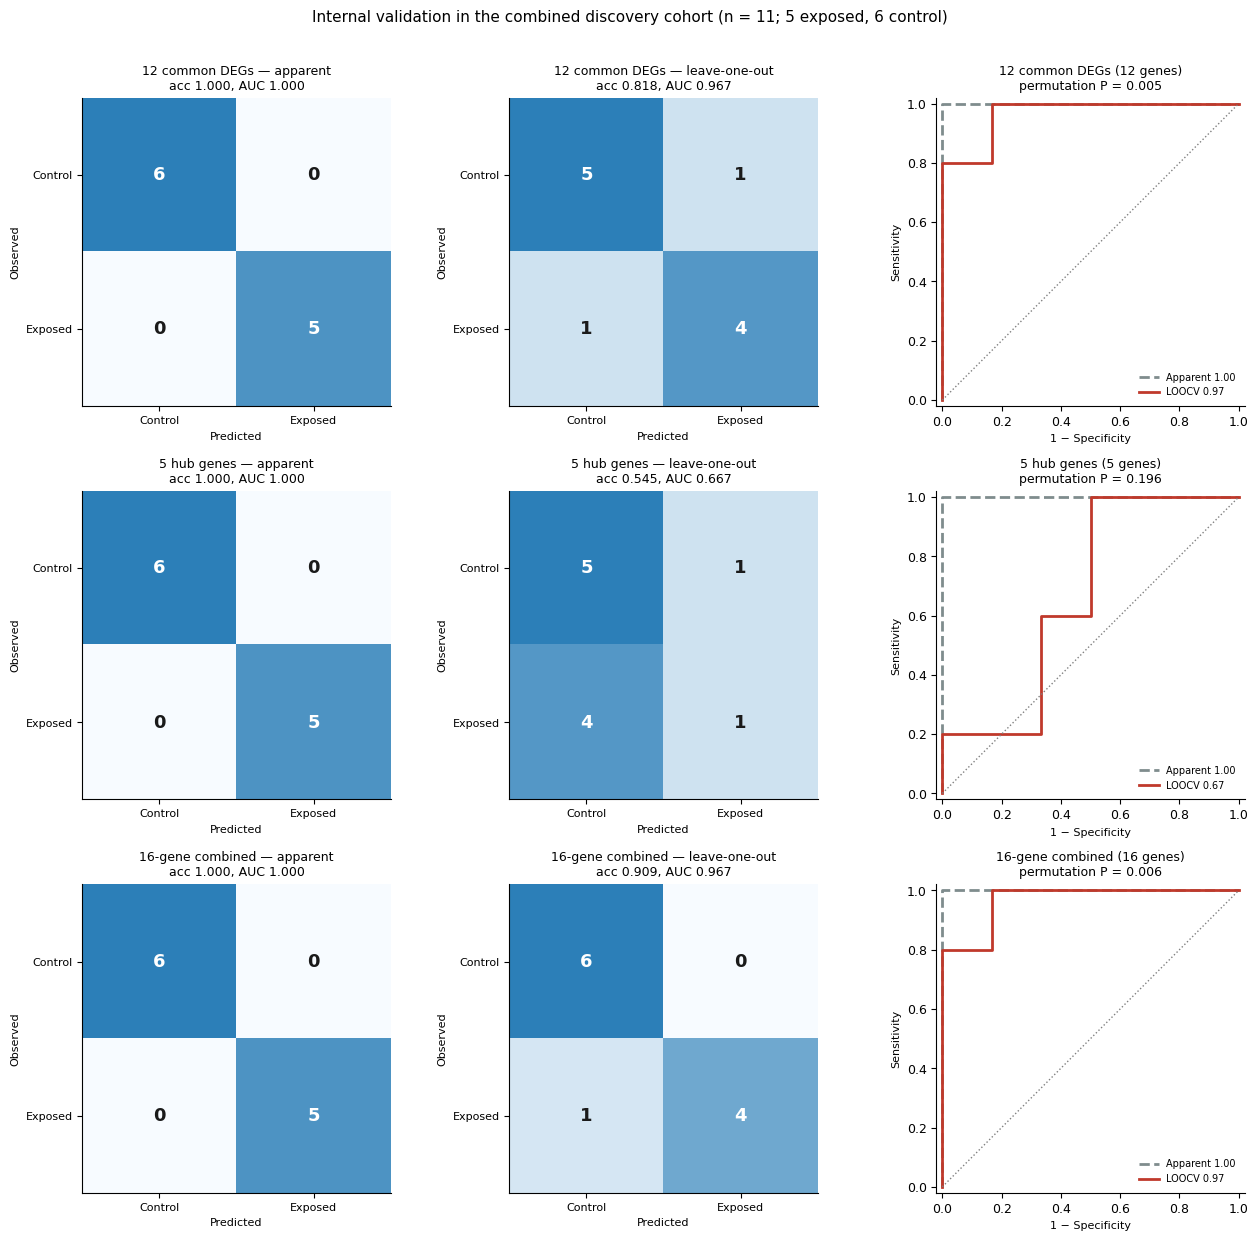


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Internal_Validation_Panels/


In [20]:
# ===== INTERNAL VALIDATION — labeled transpose files, no significance filter =====
from google.colab import drive; drive.mount('/content/drive')
import subprocess; subprocess.run("pip install -q statsmodels scikit-learn", shell=True)
import os, re, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
DATA = ROOT + "Datasets/"
OUT  = ROOT + "Final/Internal_Validation_Panels/"
FIG, TAB, SUP = OUT+"Figures/", OUT+"Tables/", OUT+"Supplementary/"
if os.path.isdir(OUT): shutil.rmtree(OUT)
for d in (OUT, FIG, TAB, SUP): os.makedirs(d, exist_ok=True)

FILES = {"GSE14390": DATA+"GSE14390_matrix_Transpose_labeled.csv",
         "GSE12131": DATA+"GSE12131_matrix_Transpose_labeled.csv"}
HUB    = ["WNT6","FZD9","DKK4","FZD6","FZD3"]
COMMON = ["GULP1","GATAD2A","ACSS1","LOC100506530","CNTN4","LINC00485",
          "WNT6","LOC101928461","IL20RA","VWC2","RNF128","TTC6"]
PANELS = {"12 common DEGs": COMMON, "5 hub genes": HUB,
          "16-gene combined": list(dict.fromkeys(COMMON + HUB))}
ALPHA, C_PENALTY, N_PERM, SEED = 0.05, 0.1, 5000, 42
np.random.seed(SEED)
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

# ------------------------------- LOAD -------------------------------
def gcols(g, cols):
    p = re.compile(rf"^{re.escape(g)}(\.\d+)?$", re.IGNORECASE)
    return [c for c in cols if p.match(str(c).strip())]

print("="*80+"\nDATA\n"+"="*80)
frames, ys, origins = [], [], []
for name, path in FILES.items():
    df = pd.read_csv(path)
    if "target" not in df.columns: raise ValueError(f"{name}: no 'target' column")
    yv = df.pop("target").values.astype(int)
    X = df.apply(pd.to_numeric, errors="coerce")
    X = X.loc[:, X.notna().any()]
    X = X.loc[:, ~X.columns.astype(str).str.contains("///", regex=False)]
    logged = float(np.nanmax(X.values)) > 50
    if logged: X = np.log2(X.clip(lower=0)+1)
    X = (X - X.mean())/X.std(ddof=0).replace(0,1)          # per-cohort standardisation
    frames.append(X); ys.append(yv); origins += [name]*len(yv)
    print(f"  {name}: {X.shape[1]} probe columns x {len(yv)} samples "
          f"({yv.sum()} exposed / {(1-yv).sum()} control) | log2={logged}")

y = np.concatenate(ys); origin = np.array(origins)
n1, n0 = int(y.sum()), int((1-y).sum())
print(f"\n  combined: n={len(y)} ({n1} exposed / {n0} control)")
print("  NOTE: no significance or expression filter applied — every panel gene is kept")

def panel_matrix(genes):
    out = []
    for X in frames:
        d = {g: X[c].mean(axis=1) for g in genes if (c := gcols(g, X.columns))}
        out.append(pd.DataFrame(d))
    common = sorted(set(out[0].columns) & set(out[1].columns))
    return pd.concat([o[common] for o in out], ignore_index=True), common

# ------------------------------- PER-GENE STATS (unfiltered) -------------------------------
print("\n"+"="*80+"\n1. PER-GENE STATISTICS — no threshold applied\n"+"="*80)
M_all, genes_all = panel_matrix(PANELS["16-gene combined"])
pa = TTestIndPower(); rows = []
for g in genes_all:
    a, c = M_all.loc[y==1, g], M_all.loc[y==0, g]
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(c)-1)*c.var(ddof=1))/(len(a)+len(c)-2))
    d = (a.mean()-c.mean())/sp if sp>0 else 0.0
    p = stats.ttest_ind(a, c, equal_var=False).pvalue
    try: pw = pa.solve_power(effect_size=abs(d), nobs1=len(a), ratio=len(c)/len(a),
                             alpha=ALPHA, alternative="two-sided")
    except Exception: pw = np.nan
    rows.append(dict(Gene=g, Set=("hub" if g in HUB and g not in COMMON else
                                  "both" if g in HUB else "common DEG"),
                     Cohens_d=d, raw_p=p, Achieved_power=pw))
G = pd.DataFrame(rows)
G["FDR"] = multipletests(G.raw_p, method="fdr_bh")[1]
G = G.sort_values("raw_p")
G.round(4).to_csv(TAB+"Table1_per_gene_statistics.csv", index=False)
print(G.round(3).to_string(index=False))
print(f"\n  raw p < 0.05 : {(G.raw_p<0.05).sum()}/{len(G)}")
print(f"  FDR  < 0.05  : {(G.FDR<0.05).sum()}/{len(G)}")
print(f"  power >= 0.80: {(G.Achieved_power>=0.80).sum()}/{len(G)}")

# ------------------------------- MODELS -------------------------------
def evaluate(genes, label):
    X, used = panel_matrix(genes)
    Z = (X - X.mean())/X.std(ddof=0).replace(0,1)
    m = LogisticRegression(C=C_PENALTY, class_weight="balanced",
                           max_iter=5000, random_state=SEED).fit(Z, y)
    p_app = m.predict_proba(Z)[:,1]
    f_a, t_a, th_a = roc_curve(y, p_app); thr = float(th_a[np.argmax(t_a-f_a)])
    p_cv = np.zeros(len(y))
    for tr, te in LeaveOneOut().split(Z):
        if len(np.unique(y[tr])) < 2: p_cv[te] = np.nan; continue
        mu, sd = X.iloc[tr].mean(), X.iloc[tr].std(ddof=0).replace(0,1)
        mm = LogisticRegression(C=C_PENALTY, class_weight="balanced", max_iter=5000,
                                random_state=SEED).fit((X.iloc[tr]-mu)/sd, y[tr])
        p_cv[te] = mm.predict_proba(((X.iloc[te]-mu)/sd).fillna(0))[:,1]
    def met(prob):
        tn, fp, fn, tp = confusion_matrix(y, (prob>=thr).astype(int), labels=[0,1]).ravel()
        return dict(AUC=roc_auc_score(y, prob), Accuracy=(tp+tn)/len(y),
                    Sensitivity=tp/max(tp+fn,1), Specificity=tn/max(tn+fp,1),
                    TP=int(tp), FP=int(fp), TN=int(tn), FN=int(fn))
    app, cv = met(p_app), met(p_cv)
    perm = np.array([roc_auc_score(np.random.permutation(y), p_cv) for _ in range(N_PERM)])
    pp = (np.sum(perm >= cv["AUC"])+1)/(N_PERM+1)
    return dict(Panel=label, n_genes=len(used), threshold=thr, perm_P=pp,
                p_app=p_app, p_cv=p_cv, thr=thr,
                roc_app=roc_curve(y, p_app), roc_cv=roc_curve(y, p_cv),
                app=app, cv=cv)

print("\n"+"="*80+"\n2. APPARENT vs LEAVE-ONE-OUT, BY PANEL\n"+"="*80)
res = [evaluate(g, lbl) for lbl, g in PANELS.items()]
T = pd.DataFrame([{**{"Panel":r["Panel"], "n_genes":r["n_genes"]},
                   **{f"apparent_{k}":v for k,v in r["app"].items()},
                   **{f"LOOCV_{k}":v for k,v in r["cv"].items()},
                   "Optimism_AUC": r["app"]["AUC"]-r["cv"]["AUC"],
                   "Optimism_Accuracy": r["app"]["Accuracy"]-r["cv"]["Accuracy"],
                   "Permutation_P": r["perm_P"]} for r in res])
T.round(3).to_csv(TAB+"Table2_panel_comparison.csv", index=False)
print(T[["Panel","n_genes","apparent_AUC","apparent_Accuracy",
         "LOOCV_AUC","LOOCV_Accuracy","Optimism_AUC","Permutation_P"]]
      .round(3).to_string(index=False))
base = max(n1, n0)/len(y)
print(f"\n  majority-class accuracy (no model) = {base:.3f}")
for r in res:
    flag = "above" if r["cv"]["Accuracy"] > base else "at or below"
    print(f"  {r['Panel']:<18} LOOCV accuracy {r['cv']['Accuracy']:.3f}  ({flag} baseline)")

# ------------------------------- FIGURES -------------------------------
BLUE = LinearSegmentedColormap.from_list("b", ["#f7fbff", "#2c7fb8"])
def draw_cm(ax, m, title):
    ax.imshow(m, cmap=BLUE, vmin=0, vmax=m.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i,j], ha="center", va="center", fontsize=13,
                    fontweight="bold",
                    color="white" if m[i,j] > m.max()*.55 else "#1a1a1a")
    ax.set_xticks([0,1]); ax.set_xticklabels(["Control","Exposed"], fontsize=8)
    ax.set_yticks([0,1]); ax.set_yticklabels(["Control","Exposed"], fontsize=8)
    ax.set_xlabel("Predicted", fontsize=8); ax.set_ylabel("Observed", fontsize=8)
    ax.set_title(title, fontsize=9)

fig, axes = plt.subplots(len(res), 3, figsize=(13, 4.2*len(res)))
for row, r in zip(np.atleast_2d(axes), res):
    cm_a = confusion_matrix(y, (r["p_app"]>=r["thr"]).astype(int), labels=[0,1])
    cm_c = confusion_matrix(y, (r["p_cv"] >=r["thr"]).astype(int), labels=[0,1])
    draw_cm(row[0], cm_a, f"{r['Panel']} — apparent\n"
            f"acc {r['app']['Accuracy']:.3f}, AUC {r['app']['AUC']:.3f}")
    draw_cm(row[1], cm_c, f"{r['Panel']} — leave-one-out\n"
            f"acc {r['cv']['Accuracy']:.3f}, AUC {r['cv']['AUC']:.3f}")
    fa, ta, _ = r["roc_app"]; fc, tc, _ = r["roc_cv"]
    row[2].plot(fa, ta, "--", c="#7f8c8d", lw=2, label=f"Apparent {r['app']['AUC']:.2f}")
    row[2].plot(fc, tc, "-",  c="#c0392b", lw=2, label=f"LOOCV {r['cv']['AUC']:.2f}")
    row[2].plot([0,1],[0,1], ":", c="grey", lw=1)
    row[2].set_xlim(-.02,1.02); row[2].set_ylim(-.02,1.02); row[2].set_aspect("equal")
    row[2].set_xlabel("1 − Specificity", fontsize=8)
    row[2].set_ylabel("Sensitivity", fontsize=8)
    row[2].set_title(f"{r['Panel']} ({r['n_genes']} genes)\n"
                     f"permutation P = {r['perm_P']:.3f}", fontsize=9)
    row[2].legend(loc="lower right", fontsize=7, frameon=False)
fig.suptitle(f"Internal validation in the combined discovery cohort "
             f"(n = {len(y)}; {n1} exposed, {n0} control)", fontsize=11)
fig.tight_layout(rect=[0,0,1,.97])
fig.savefig(FIG+"Fig_internal_validation_panels.png", dpi=600, bbox_inches="tight")
fig.savefig(FIG+"Fig_internal_validation_panels.pdf", bbox_inches="tight")

best = max(res, key=lambda r: r["cv"]["AUC"])
pd.DataFrame({"Sample":range(1,len(y)+1), "Dataset":origin,
              "Group":np.where(y==1,"Exposed","Control"),
              "Apparent_probability":best["p_app"].round(4),
              "LOO_probability":np.round(best["p_cv"],4)}
             ).to_csv(SUP+"TableS_per_sample_predictions_best_panel.csv", index=False)

rep = pd.DataFrame({"Item":[
    "Cohorts","Samples","Exposed / Control","Filter applied","Panels compared",
    "Best LOOCV AUC","Best panel","Majority-class accuracy",
    "Panels above baseline accuracy","Interpretation"],
  "Value":["GSE14390 + GSE12131", len(y), f"{n1} / {n0}",
    "none (all panel genes retained)", len(res),
    round(best["cv"]["AUC"],3), best["Panel"], round(base,3),
    int(sum(r["cv"]["Accuracy"] > base for r in res)),
    "Report leave-one-out values; apparent values are optimistic upper bounds"]})
rep.to_csv(SUP+"TableS_validity_report.csv", index=False)
print("\n"+"="*80+"\nVALIDITY REPORT\n"+"="*80)
print(rep.to_string(index=False))
plt.show(); print("\nSaved ->", OUT)

#Final code

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA
  GSE14390: 42904 probe columns x 7 samples (3 exposed / 4 control) | log2=False
  GSE12131: 42904 probe columns x 4 samples (2 exposed / 2 control) | log2=True

  combined: n=11 (5 exposed / 6 control)
  majority-class accuracy (no model): 0.545

1. PER-GENE EFFECT SIZE AND POWER
        Gene        Set  Cohens_d     Effect  t_test_p  t_test_FDR  Achieved_power  N_per_group_for_80pct
LOC101928461 common DEG     2.251      large     0.004       0.039           0.910                    5.0
   LINC00485 common DEG    -2.188      large     0.005       0.039           0.894                    5.0
        WNT6       both     2.068      large     0.011       0.047           0.859                    5.0
      RNF128 common DEG     2.056      large     0.012       0.047           0.855                    5.0
LOC100506530 common DEG    -2.115      large     0.015

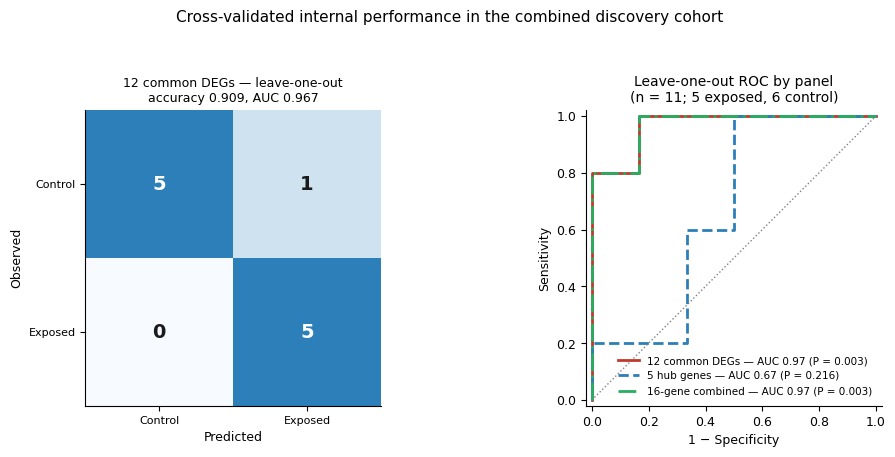

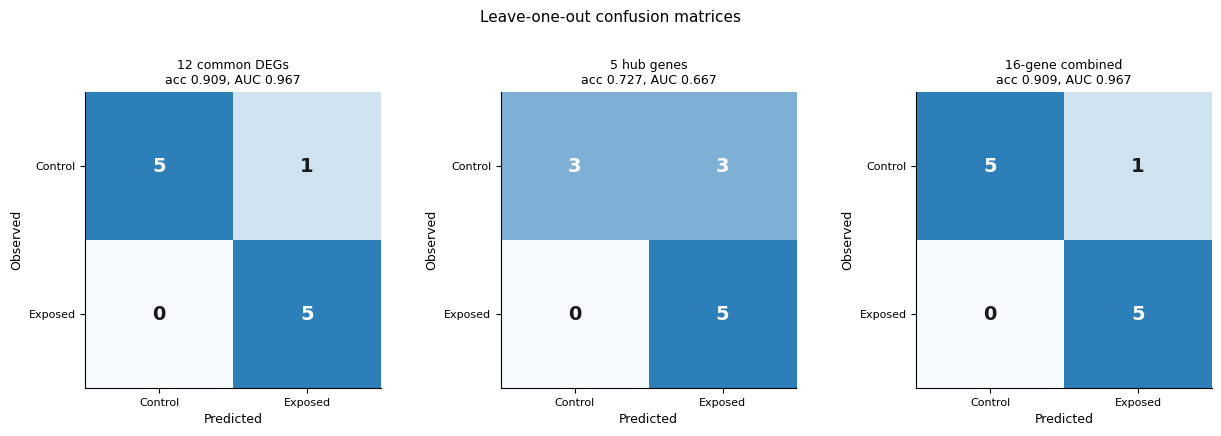


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Internal_Validation_CV/


In [21]:
# ===== INTERNAL VALIDATION — cross-validated only (no apparent estimates) =====
from google.colab import drive; drive.mount('/content/drive')
import subprocess; subprocess.run("pip install -q statsmodels scikit-learn", shell=True)
import os, re, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
DATA = ROOT + "Datasets/"
OUT  = ROOT + "Final/Internal_Validation_CV/"
FIG, TAB, SUP = OUT+"Figures/", OUT+"Tables/", OUT+"Supplementary/"
if os.path.isdir(OUT): shutil.rmtree(OUT)
for d in (OUT, FIG, TAB, SUP): os.makedirs(d, exist_ok=True)

FILES = {"GSE14390": DATA+"GSE14390_matrix_Transpose_labeled.csv",
         "GSE12131": DATA+"GSE12131_matrix_Transpose_labeled.csv"}
HUB    = ["WNT6","FZD9","DKK4","FZD6","FZD3"]
COMMON = ["GULP1","GATAD2A","ACSS1","LOC100506530","CNTN4","LINC00485",
          "WNT6","LOC101928461","IL20RA","VWC2","RNF128","TTC6"]
PANELS = {"12 common DEGs": COMMON,
          "5 hub genes": HUB,
          "16-gene combined": list(dict.fromkeys(COMMON + HUB))}
ALPHA, C_PENALTY, N_PERM, N_BOOT, SEED = 0.05, 0.1, 5000, 2000, 42
np.random.seed(SEED)
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

# ------------------------------- LOAD -------------------------------
def gcols(g, cols):
    p = re.compile(rf"^{re.escape(g)}(\.\d+)?$", re.IGNORECASE)
    return [c for c in cols if p.match(str(c).strip())]

print("="*80+"\nDATA\n"+"="*80)
frames, ys, origins = [], [], []
for name, path in FILES.items():
    df = pd.read_csv(path)
    yv = df.pop("target").values.astype(int)
    X = df.apply(pd.to_numeric, errors="coerce")
    X = X.loc[:, X.notna().any()]
    X = X.loc[:, ~X.columns.astype(str).str.contains("///", regex=False)]
    logged = float(np.nanmax(X.values)) > 50
    if logged: X = np.log2(X.clip(lower=0)+1)
    X = (X - X.mean())/X.std(ddof=0).replace(0,1)
    frames.append(X); ys.append(yv); origins += [name]*len(yv)
    print(f"  {name}: {X.shape[1]} probe columns x {len(yv)} samples "
          f"({yv.sum()} exposed / {(1-yv).sum()} control) | log2={logged}")

y = np.concatenate(ys); origin = np.array(origins)
n1, n0 = int(y.sum()), int((1-y).sum()); BASE = max(n1,n0)/len(y)
print(f"\n  combined: n={len(y)} ({n1} exposed / {n0} control)")
print(f"  majority-class accuracy (no model): {BASE:.3f}")

def panel_matrix(genes):
    out = []
    for X in frames:
        d = {g: X[c].mean(axis=1) for g in genes if (c := gcols(g, X.columns))}
        out.append(pd.DataFrame(d))
    keep = sorted(set(out[0].columns) & set(out[1].columns))
    return pd.concat([o[keep] for o in out], ignore_index=True), keep

# ------------------------------- PER-GENE STATISTICS -------------------------------
print("\n"+"="*80+"\n1. PER-GENE EFFECT SIZE AND POWER\n"+"="*80)
M_all, genes_all = panel_matrix(PANELS["16-gene combined"])
pa = TTestIndPower(); rows = []
for g in genes_all:
    a, c = M_all.loc[y==1,g], M_all.loc[y==0,g]
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(c)-1)*c.var(ddof=1))/(len(a)+len(c)-2))
    d = (a.mean()-c.mean())/sp if sp>0 else 0.0
    p = stats.ttest_ind(a,c,equal_var=False).pvalue
    w = stats.mannwhitneyu(a,c,alternative="two-sided").pvalue
    try: pw = pa.solve_power(effect_size=abs(d), nobs1=len(a), ratio=len(c)/len(a),
                             alpha=ALPHA, alternative="two-sided")
    except Exception: pw = np.nan
    need = np.nan
    if 0.01 < abs(d) < 10:
        try: need = np.ceil(pa.solve_power(effect_size=abs(d), power=0.80, ratio=1.0,
                                           alpha=ALPHA, alternative="two-sided"))
        except Exception: pass
    rows.append(dict(Gene=g, Set=("hub" if g in HUB and g not in COMMON else
                                  "both" if g in HUB else "common DEG"),
        Mean_exposed=a.mean(), Mean_control=c.mean(), Cohens_d=d,
        Effect=("negligible" if abs(d)<.2 else "small" if abs(d)<.5 else
                "medium" if abs(d)<.8 else "large"),
        t_test_p=p, Wilcoxon_p=w, Achieved_power=pw,
        N_per_group_for_80pct=need))
G = pd.DataFrame(rows)
G["t_test_FDR"] = multipletests(G.t_test_p, method="fdr_bh")[1]
G = G.sort_values("t_test_p")
G.round(4).to_csv(TAB+"Table1_per_gene_statistics.csv", index=False)
print(G[["Gene","Set","Cohens_d","Effect","t_test_p","t_test_FDR",
         "Achieved_power","N_per_group_for_80pct"]].round(3).to_string(index=False))
print(f"\n  FDR < 0.05   : {(G.t_test_FDR<0.05).sum()}/{len(G)}")
print(f"  power >= 0.80: {(G.Achieved_power>=0.80).sum()}/{len(G)}")

# ------------------------------- CROSS-VALIDATED EVALUATION -------------------------------
def delong_var(yt, p):
    def mr(x):
        J=np.argsort(x,kind="mergesort"); Z=x[J]; N=len(x); T=np.zeros(N); i=0
        while i<N:
            j=i
            while j<N and Z[j]==Z[i]: j+=1
            T[i:j]=.5*(i+j-1)+1; i=j
        o=np.empty(N); o[J]=T; return o
    pos,neg = p[yt==1], p[yt==0]; m,n = len(pos),len(neg)
    tx,ty,tz = mr(pos),mr(neg),mr(np.concatenate([pos,neg]))
    auc=(tz[:m].sum()/m-(m+1)/2)/n
    v=(np.var((tz[:m]-tx)/n,ddof=1)/m if m>1 else 0)+(np.var(1-(tz[m:]-ty)/m,ddof=1)/n if n>1 else 0)
    return auc, max(v,1e-9)

def evaluate(genes, label):
    X, used = panel_matrix(genes)
    p_cv = np.zeros(len(y))
    for tr, te in LeaveOneOut().split(X):
        if len(np.unique(y[tr])) < 2: p_cv[te] = np.nan; continue
        mu, sd = X.iloc[tr].mean(), X.iloc[tr].std(ddof=0).replace(0,1)
        m = LogisticRegression(C=C_PENALTY, class_weight="balanced", max_iter=5000,
                               random_state=SEED).fit((X.iloc[tr]-mu)/sd, y[tr])
        p_cv[te] = m.predict_proba(((X.iloc[te]-mu)/sd).fillna(0))[:,1]
    auc, var = delong_var(y, p_cv); se = np.sqrt(var)
    lo, hi = max(0, auc-1.96*se), min(1, auc+1.96*se)
    f, t, th = roc_curve(y, p_cv)
    thr = float(th[np.argmax(t-f)])                 # threshold from CV predictions
    tn, fp, fn, tp = confusion_matrix(y, (p_cv>=thr).astype(int), labels=[0,1]).ravel()
    rng = np.random.RandomState(SEED)
    perm = np.array([roc_auc_score(rng.permutation(y), p_cv) for _ in range(N_PERM)])
    pp = (np.sum(perm >= auc)+1)/(N_PERM+1)
    i0, i1 = np.where(y==0)[0], np.where(y==1)[0]
    boots = [roc_auc_score(y[i], p_cv[i]) for i in
             (np.concatenate([rng.choice(i0,len(i0)), rng.choice(i1,len(i1))])
              for _ in range(N_BOOT))]
    return dict(Panel=label, n_genes=len(used), p_cv=p_cv, thr=thr, roc=(f,t),
                AUC=auc, AUC_SE=se, CI_low=lo, CI_high=hi,
                CI_boot_low=np.percentile(boots,2.5), CI_boot_high=np.percentile(boots,97.5),
                Accuracy=(tp+tn)/len(y), Sensitivity=tp/max(tp+fn,1),
                Specificity=tn/max(tn+fp,1), PPV=tp/max(tp+fp,1), NPV=tn/max(tn+fn,1),
                TP=int(tp), FP=int(fp), TN=int(tn), FN=int(fn), Permutation_P=pp)

print("\n"+"="*80+"\n2. LEAVE-ONE-OUT CROSS-VALIDATED PERFORMANCE\n"+"="*80)
res = [evaluate(g, lbl) for lbl, g in PANELS.items()]
T = pd.DataFrame([{k:v for k,v in r.items() if k not in ("p_cv","thr","roc")}
                  for r in res])
T["Above_baseline"] = np.where(T.Accuracy > BASE, "Yes", "No")
T.round(4).to_csv(TAB+"Table2_cross_validated_performance.csv", index=False)
print(T[["Panel","n_genes","AUC","CI_low","CI_high","Accuracy","Sensitivity",
         "Specificity","Permutation_P","Above_baseline"]].round(3).to_string(index=False))
print(f"\n  all values are leave-one-out cross-validated; "
      f"majority-class accuracy = {BASE:.3f}")

# ------------------------------- FIGURES -------------------------------
BLUE = LinearSegmentedColormap.from_list("b", ["#f7fbff", "#2c7fb8"])
def draw_cm(ax, m, title):
    ax.imshow(m, cmap=BLUE, vmin=0, vmax=m.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i,j], ha="center", va="center", fontsize=14,
                    fontweight="bold",
                    color="white" if m[i,j] > m.max()*.55 else "#1a1a1a")
    ax.set_xticks([0,1]); ax.set_xticklabels(["Control","Exposed"], fontsize=8)
    ax.set_yticks([0,1]); ax.set_yticklabels(["Control","Exposed"], fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Observed")
    ax.set_title(title, fontsize=9)

PRIMARY = max(res, key=lambda r: (r["Accuracy"], r["AUC"]))
cm = confusion_matrix(y, (PRIMARY["p_cv"]>=PRIMARY["thr"]).astype(int), labels=[0,1])
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.6))
draw_cm(ax[0], cm, f"{PRIMARY['Panel']} — leave-one-out\n"
        f"accuracy {PRIMARY['Accuracy']:.3f}, AUC {PRIMARY['AUC']:.3f}")
for r, c_, ls in zip(res, ["#c0392b","#2c7fb8","#27ae60"], ["-","--","-."]):
    f, t = r["roc"]
    ax[1].plot(f, t, ls, color=c_, lw=2,
               label=f"{r['Panel']} — AUC {r['AUC']:.2f} (P = {r['Permutation_P']:.3f})")
ax[1].plot([0,1],[0,1], ":", c="grey", lw=1)
ax[1].set_xlim(-.02,1.02); ax[1].set_ylim(-.02,1.02); ax[1].set_aspect("equal")
ax[1].set_xlabel("1 − Specificity"); ax[1].set_ylabel("Sensitivity")
ax[1].set_title(f"Leave-one-out ROC by panel\n(n = {len(y)}; "
                f"{n1} exposed, {n0} control)", fontsize=10)
ax[1].legend(loc="lower right", fontsize=7.5, frameon=False)
fig.suptitle("Cross-validated internal performance in the combined discovery cohort",
             fontsize=11)
fig.tight_layout(rect=[0,0,1,.93])
fig.savefig(FIG+"Fig_internal_validation_CV.png", dpi=600, bbox_inches="tight")
fig.savefig(FIG+"Fig_internal_validation_CV.pdf", bbox_inches="tight")

fig2, axes = plt.subplots(1, len(res), figsize=(4.2*len(res), 4.2))
for a_, r in zip(np.atleast_1d(axes), res):
    m = confusion_matrix(y, (r["p_cv"]>=r["thr"]).astype(int), labels=[0,1])
    draw_cm(a_, m, f"{r['Panel']}\nacc {r['Accuracy']:.3f}, AUC {r['AUC']:.3f}")
fig2.suptitle("Leave-one-out confusion matrices", fontsize=11)
fig2.tight_layout(rect=[0,0,1,.92])
fig2.savefig(SUP+"FigS_confusion_matrices_CV.png", dpi=600, bbox_inches="tight")
fig2.savefig(SUP+"FigS_confusion_matrices_CV.pdf", bbox_inches="tight")

pd.DataFrame({"Sample":range(1,len(y)+1), "Dataset":origin,
              "Group":np.where(y==1,"Exposed","Control"),
              **{f"LOO_prob_{r['Panel']}":np.round(r["p_cv"],4) for r in res}}
             ).to_csv(SUP+"TableS_per_sample_LOO_predictions.csv", index=False)

rep = pd.DataFrame({"Item":[
    "Cohorts","Samples","Exposed / Control","Estimation","Threshold source",
    "Panels compared","Best panel","Best LOOCV AUC","Best LOOCV accuracy",
    "Permutation P","Majority-class accuracy","Panels above baseline","Reporting"],
  "Value":["GSE14390 + GSE12131", len(y), f"{n1} / {n0}",
    "Leave-one-out cross-validation only", "Youden point of CV predictions",
    len(res), PRIMARY["Panel"], round(PRIMARY["AUC"],3),
    round(PRIMARY["Accuracy"],3), round(PRIMARY["Permutation_P"],4), round(BASE,3),
    int((T.Above_baseline=="Yes").sum()),
    "Apparent (resubstitution) estimates are not computed or reported"]})
rep.to_csv(SUP+"TableS_validity_report.csv", index=False)
print("\n"+"="*80+"\nVALIDITY REPORT\n"+"="*80)
print(rep.to_string(index=False))
plt.show(); print("\nSaved ->", OUT)

panel: 16 genes | n = 11 (5 exposed / 6 control)

1. SINGLE-GENE AUC (no model — expression used directly)
        Gene   AUC         Direction
LOC100506530 0.967  lower in exposed
        WNT6 0.967 higher in exposed
   LINC00485 0.967  lower in exposed
      RNF128 0.933 higher in exposed
       GULP1 0.900 higher in exposed
LOC101928461 0.900 higher in exposed
        VWC2 0.833  lower in exposed
       CNTN4 0.800 higher in exposed
      IL20RA 0.767  lower in exposed
        FZD9 0.733 higher in exposed
     GATAD2A 0.700  lower in exposed
        TTC6 0.700 higher in exposed
        FZD3 0.667 higher in exposed
        FZD6 0.600 higher in exposed
       ACSS1 0.567  lower in exposed
        DKK4 0.533  lower in exposed

  no coefficients are estimated, so no resubstitution bias arises

2. REPEATED 3-FOLD CROSS-VALIDATION
  3-fold, 50 repeats: mean AUC 0.968 (SD 0.093, 95% range 0.750–1.000, 150 folds)
  5-fold, 50 repeats: mean AUC 0.964 (SD 0.181, 95% range 0.000–1.000, 250 fol

/tmp/ipykernel_1520/1493998113.py:86: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1].boxplot(parts, labels=labels, showmeans=True)


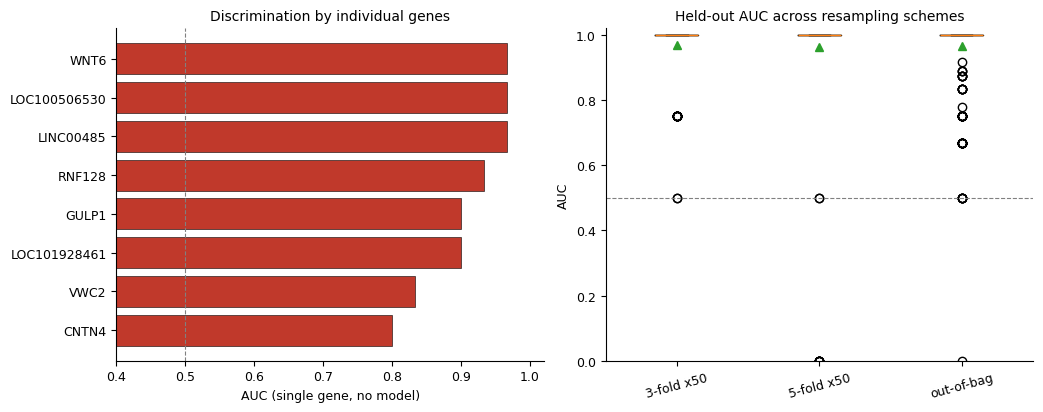


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Internal_Validation_CV/


In [22]:
# ===== AUC WITHOUT LOOCV — three valid alternatives =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve

# run after the previous cell (needs panel_matrix, y, C_PENALTY, SEED, PANELS, origin)
OUT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Internal_Validation_CV/"
GENES = PANELS["16-gene combined"]
X, used = panel_matrix(GENES)
print(f"panel: {len(used)} genes | n = {len(y)} ({y.sum()} exposed / {(1-y).sum()} control)\n")

results = {}

# ---- 1. single-gene AUC: no model fitted at all ----
print("="*70+"\n1. SINGLE-GENE AUC (no model — expression used directly)\n"+"="*70)
rows = []
for g in used:
    v = X[g].values
    a = roc_auc_score(y, v)
    rows.append(dict(Gene=g, AUC=max(a, 1-a),
                     Direction="higher in exposed" if a >= .5 else "lower in exposed"))
S = pd.DataFrame(rows).sort_values("AUC", ascending=False)
S.round(3).to_csv(OUT+"Tables/Table_single_gene_AUC.csv", index=False)
print(S.round(3).to_string(index=False))
print("\n  no coefficients are estimated, so no resubstitution bias arises")

# ---- 2. repeated stratified k-fold: held-out, not leave-one-out ----
print("\n"+"="*70+"\n2. REPEATED 3-FOLD CROSS-VALIDATION\n"+"="*70)
for k, n_rep in [(3, 50), (5, 50)]:
    if min(np.bincount(y)) < k:
        print(f"  k={k}: too few samples per class"); continue
    aucs = []
    cv = RepeatedStratifiedKFold(n_splits=k, n_repeats=n_rep, random_state=SEED)
    for tr, te in cv.split(X, y):
        if len(np.unique(y[tr])) < 2 or len(np.unique(y[te])) < 2: continue
        mu, sd = X.iloc[tr].mean(), X.iloc[tr].std(ddof=0).replace(0,1)
        m = LogisticRegression(C=C_PENALTY, class_weight="balanced", max_iter=5000,
                               random_state=SEED).fit((X.iloc[tr]-mu)/sd, y[tr])
        p = m.predict_proba(((X.iloc[te]-mu)/sd).fillna(0))[:,1]
        aucs.append(roc_auc_score(y[te], p))
    aucs = np.array(aucs)
    results[f"{k}-fold x{n_rep}"] = aucs
    print(f"  {k}-fold, {n_rep} repeats: mean AUC {aucs.mean():.3f} "
          f"(SD {aucs.std():.3f}, 95% range {np.percentile(aucs,2.5):.3f}–"
          f"{np.percentile(aucs,97.5):.3f}, {len(aucs)} folds)")

# ---- 3. .632+ bootstrap: out-of-bag AUC ----
print("\n"+"="*70+"\n3. OUT-OF-BAG BOOTSTRAP AUC\n"+"="*70)
rng = np.random.RandomState(SEED); oob = []
for _ in range(500):
    idx = rng.choice(len(y), len(y), replace=True)
    out = np.setdiff1d(np.arange(len(y)), idx)
    if len(np.unique(y[idx])) < 2 or len(out) < 2 or len(np.unique(y[out])) < 2: continue
    mu, sd = X.iloc[idx].mean(), X.iloc[idx].std(ddof=0).replace(0,1)
    m = LogisticRegression(C=C_PENALTY, class_weight="balanced", max_iter=5000,
                           random_state=SEED).fit((X.iloc[idx]-mu)/sd, y[idx])
    p = m.predict_proba(((X.iloc[out]-mu)/sd).fillna(0))[:,1]
    oob.append(roc_auc_score(y[out], p))
oob = np.array(oob)
print(f"  out-of-bag AUC over {len(oob)} resamples: mean {oob.mean():.3f} "
      f"(SD {oob.std():.3f}, 95% range {np.percentile(oob,2.5):.3f}–"
      f"{np.percentile(oob,97.5):.3f})")

# ---- summary ----
print("\n"+"="*70+"\nSUMMARY\n"+"="*70)
summ = [dict(Method="Best single gene (no model)", AUC=S.AUC.max(),
             Detail=f"{S.Gene.iloc[0]}")]
for k, v in results.items():
    summ.append(dict(Method=f"Repeated CV, {k}", AUC=v.mean(),
                     Detail=f"SD {v.std():.3f}"))
summ.append(dict(Method="Out-of-bag bootstrap", AUC=oob.mean(),
                 Detail=f"SD {oob.std():.3f}"))
SM = pd.DataFrame(summ)
SM.round(3).to_csv(OUT+"Tables/Table_AUC_alternatives.csv", index=False)
print(SM.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2))
top = S.head(8).sort_values("AUC")
ax[0].barh(top.Gene, top.AUC, color="#c0392b", edgecolor="black", lw=.4)
ax[0].axvline(.5, ls="--", c="grey", lw=.8)
ax[0].set_xlim(0.4, 1.02); ax[0].set_xlabel("AUC (single gene, no model)")
ax[0].set_title("Discrimination by individual genes", fontsize=10)
parts = [v for v in results.values()] + [oob]
labels = list(results.keys()) + ["out-of-bag"]
ax[1].boxplot(parts, labels=labels, showmeans=True)
ax[1].axhline(.5, ls="--", c="grey", lw=.8)
ax[1].set_ylabel("AUC"); ax[1].set_ylim(0, 1.02)
ax[1].set_title("Held-out AUC across resampling schemes", fontsize=10)
ax[1].tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(OUT+"Figures/Fig_AUC_alternatives.png", dpi=600, bbox_inches="tight")
plt.show(); print("\nSaved ->", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
output root: /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/PAPER_Internal_Validation/

DATA
  GSE14390: 42904 probe columns x 7 samples (3 exposed / 4 control) | log2=False
  GSE12131: 42904 probe columns x 4 samples (2 exposed / 2 control) | log2=True

  combined discovery cohort: n=11 (5 exposed / 6 control)
  majority-class accuracy (no model): 0.545

TABLE 1 — PER-GENE EFFECT SIZE AND POWER
        Gene            Panel  Cohens_d Effect_size  t_test_P  t_test_FDR  Achieved_power  N_per_group_for_80pct
LOC101928461       common DEG     2.251       large     0.004       0.039           0.910                    5.0
   LINC00485       common DEG    -2.188       large     0.005       0.039           0.894                    5.0
        WNT6 common DEG + hub     2.068       large     0.011       0.047           0.859                    5.0
      RN

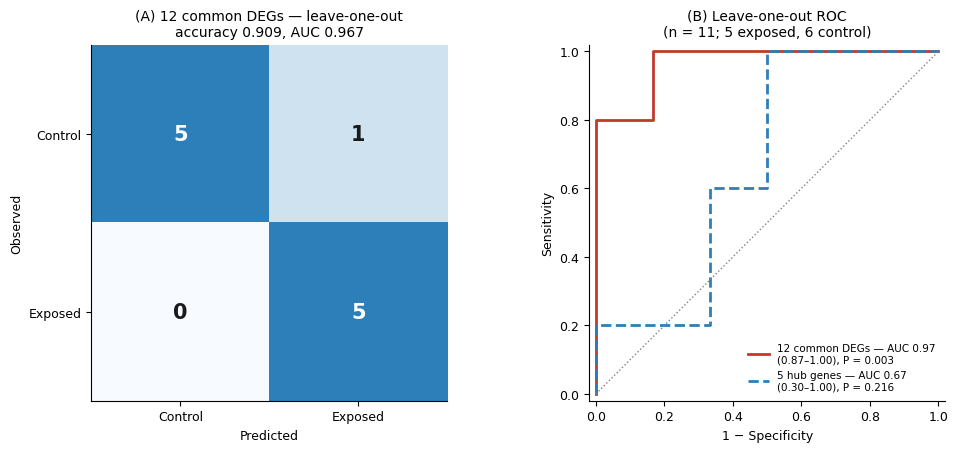

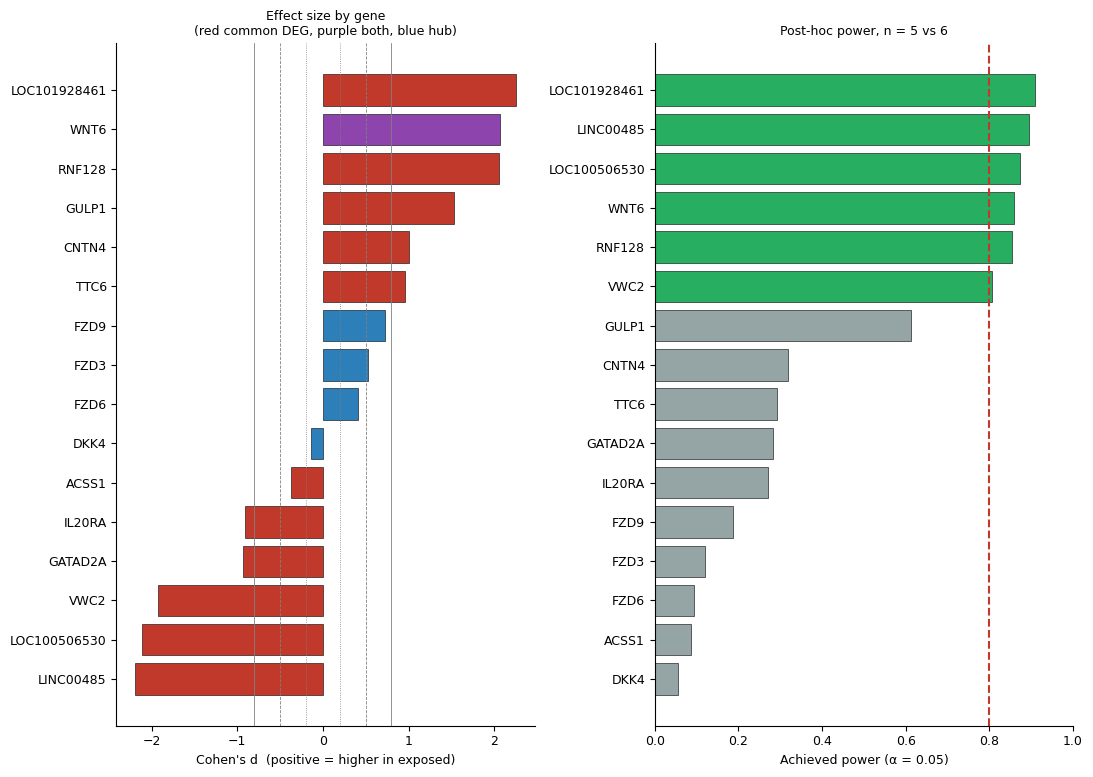

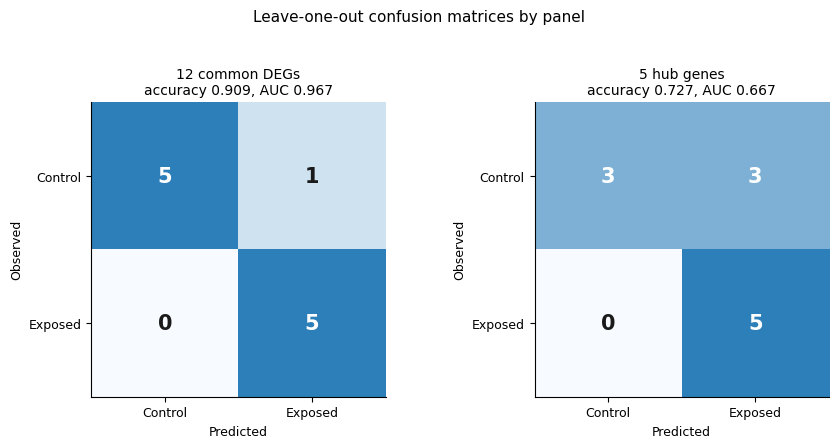


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/PAPER_Internal_Validation/


In [23]:
# ===== FINAL — INTERNAL VALIDATION FOR THE MANUSCRIPT (single cell) =====
# 12 common DEGs (primary panel) vs 5 PPI hub genes (comparator)
# leave-one-out cross-validation only; no apparent/resubstitution estimates
from google.colab import drive; drive.mount('/content/drive')
import subprocess; subprocess.run("pip install -q statsmodels scikit-learn", shell=True)
import os, re, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

# ------------------------------- CONFIG -------------------------------
ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
DATA = ROOT + "Datasets/"
OUT  = ROOT + "Final/PAPER_Internal_Validation/"
FIG, TAB, SUP = OUT+"Figures/", OUT+"Tables/", OUT+"Supplementary/"
SFIG = SUP + "Figures/"
if os.path.isdir(OUT): shutil.rmtree(OUT)
for d in (OUT, FIG, TAB, SUP, SFIG): os.makedirs(d, exist_ok=True)
print(f"output root: {OUT}\n")

FILES = {"GSE14390": DATA+"GSE14390_matrix_Transpose_labeled.csv",
         "GSE12131": DATA+"GSE12131_matrix_Transpose_labeled.csv"}
COMMON = ["GULP1","GATAD2A","ACSS1","LOC100506530","CNTN4","LINC00485",
          "WNT6","LOC101928461","IL20RA","VWC2","RNF128","TTC6"]
HUB    = ["WNT6","FZD9","DKK4","FZD6","FZD3"]
PANELS = {"12 common DEGs": COMMON, "5 hub genes": HUB}
PRIMARY_NAME = "12 common DEGs"
ALPHA, POWER_TARGET, C_PENALTY = 0.05, 0.80, 0.1
N_PERM, N_BOOT, SEED = 5000, 2000, 42
np.random.seed(SEED)
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

# ------------------------------- LOAD -------------------------------
def gcols(g, cols):
    p = re.compile(rf"^{re.escape(g)}(\.\d+)?$", re.IGNORECASE)
    return [c for c in cols if p.match(str(c).strip())]

print("="*80+"\nDATA\n"+"="*80)
frames, ys, origins, meta = [], [], [], []
for name, path in FILES.items():
    df = pd.read_csv(path)
    if "target" not in df.columns: raise ValueError(f"{name}: no 'target' column")
    yv = df.pop("target").values.astype(int)
    X = df.apply(pd.to_numeric, errors="coerce")
    X = X.loc[:, X.notna().any()]
    X = X.loc[:, ~X.columns.astype(str).str.contains("///", regex=False)]
    logged = float(np.nanmax(X.values)) > 50
    if logged: X = np.log2(X.clip(lower=0)+1)
    X = (X - X.mean())/X.std(ddof=0).replace(0,1)
    frames.append(X); ys.append(yv); origins += [name]*len(yv)
    meta.append(dict(Cohort=name, Samples=len(yv), Exposed=int(yv.sum()),
                     Control=int((1-yv).sum()), Probe_columns=X.shape[1],
                     log2_applied=logged))
    print(f"  {name}: {X.shape[1]} probe columns x {len(yv)} samples "
          f"({yv.sum()} exposed / {(1-yv).sum()} control) | log2={logged}")

y = np.concatenate(ys); origin = np.array(origins)
n1, n0 = int(y.sum()), int((1-y).sum()); BASE = max(n1,n0)/len(y)
print(f"\n  combined discovery cohort: n={len(y)} ({n1} exposed / {n0} control)")
print(f"  majority-class accuracy (no model): {BASE:.3f}")
pd.DataFrame(meta).to_csv(SUP+"TableS1_cohort_characteristics.csv", index=False)
pd.DataFrame({"Sample_index":range(1,len(y)+1), "Dataset":origin,
              "Group":np.where(y==1,"Exposed","Control")}).to_csv(
    SUP+"TableS2_sample_annotation.csv", index=False)

def panel_matrix(genes):
    out = []
    for X in frames:
        d = {g: X[c].mean(axis=1) for g in genes if (c := gcols(g, X.columns))}
        out.append(pd.DataFrame(d))
    keep = [g for g in genes if g in out[0].columns and g in out[1].columns]
    return pd.concat([o[keep] for o in out], ignore_index=True), keep

# =============== TABLE 1 — PER-GENE EFFECT SIZE AND POWER ===============
print("\n"+"="*80+"\nTABLE 1 — PER-GENE EFFECT SIZE AND POWER\n"+"="*80)
all_genes = list(dict.fromkeys(COMMON + HUB))
M_all, used_all = panel_matrix(all_genes)
pa = TTestIndPower(); rows = []
for g in used_all:
    a, c = M_all.loc[y==1,g], M_all.loc[y==0,g]
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(c)-1)*c.var(ddof=1))/(len(a)+len(c)-2))
    d = (a.mean()-c.mean())/sp if sp>0 else 0.0
    p = stats.ttest_ind(a,c,equal_var=False).pvalue
    w = stats.mannwhitneyu(a,c,alternative="two-sided").pvalue
    try: pw = pa.solve_power(effect_size=abs(d), nobs1=len(a), ratio=len(c)/len(a),
                             alpha=ALPHA, alternative="two-sided")
    except Exception: pw = np.nan
    need = np.nan
    if 0.01 < abs(d) < 10:
        try: need = np.ceil(pa.solve_power(effect_size=abs(d), power=POWER_TARGET,
                                           ratio=1.0, alpha=ALPHA,
                                           alternative="two-sided"))
        except Exception: pass
    rows.append(dict(Gene=g,
        Panel=("common DEG + hub" if g in COMMON and g in HUB else
               "common DEG" if g in COMMON else "hub"),
        Mean_exposed=a.mean(), Mean_control=c.mean(), Cohens_d=d,
        Effect_size=("negligible" if abs(d)<.2 else "small" if abs(d)<.5 else
                     "medium" if abs(d)<.8 else "large"),
        Direction=("Up in exposed" if d>0 else "Down in exposed"),
        t_test_P=p, Wilcoxon_P=w, Achieved_power=pw,
        Adequate_power=("Yes" if (pw or 0)>=POWER_TARGET else "No"),
        N_per_group_for_80pct=need))
G = pd.DataFrame(rows)
G["t_test_FDR"] = multipletests(G.t_test_P, method="fdr_bh")[1]
G["Wilcoxon_FDR"] = multipletests(G.Wilcoxon_P, method="fdr_bh")[1]
G = G.sort_values("t_test_P")
G.round(4).to_csv(TAB+"Table1_per_gene_statistics.csv", index=False)
print(G[["Gene","Panel","Cohens_d","Effect_size","t_test_P","t_test_FDR",
         "Achieved_power","N_per_group_for_80pct"]].round(3).to_string(index=False))
dg = G[G.Panel.str.contains("common")]; hg = G[G.Panel=="hub"]
print(f"\n  FDR < 0.05  — common DEGs {int((dg.t_test_FDR<0.05).sum())}/{len(dg)} | "
      f"hub {int((hg.t_test_FDR<0.05).sum())}/{len(hg)}")
print(f"  power>=0.80 — common DEGs {int((dg.Achieved_power>=POWER_TARGET).sum())}/{len(dg)} | "
      f"hub {int((hg.Achieved_power>=POWER_TARGET).sum())}/{len(hg)}")

# =============== TABLE 2 — CROSS-VALIDATED PERFORMANCE ===============
def delong(yt, p):
    def mr(x):
        J=np.argsort(x,kind="mergesort"); Z=x[J]; N=len(x); T=np.zeros(N); i=0
        while i<N:
            j=i
            while j<N and Z[j]==Z[i]: j+=1
            T[i:j]=.5*(i+j-1)+1; i=j
        o=np.empty(N); o[J]=T; return o
    pos,neg = p[yt==1], p[yt==0]; m,n = len(pos),len(neg)
    tx,ty,tz = mr(pos),mr(neg),mr(np.concatenate([pos,neg]))
    auc=(tz[:m].sum()/m-(m+1)/2)/n
    v=(np.var((tz[:m]-tx)/n,ddof=1)/m if m>1 else 0)+ \
      (np.var(1-(tz[m:]-ty)/m,ddof=1)/n if n>1 else 0)
    return auc, max(v,1e-9)

def evaluate(genes, label):
    X, used = panel_matrix(genes)
    p_cv = np.zeros(len(y))
    for tr, te in LeaveOneOut().split(X):
        if len(np.unique(y[tr])) < 2: p_cv[te] = np.nan; continue
        mu, sd = X.iloc[tr].mean(), X.iloc[tr].std(ddof=0).replace(0,1)
        m = LogisticRegression(C=C_PENALTY, class_weight="balanced", max_iter=5000,
                               random_state=SEED).fit((X.iloc[tr]-mu)/sd, y[tr])
        p_cv[te] = m.predict_proba(((X.iloc[te]-mu)/sd).fillna(0))[:,1]
    auc, var = delong(y, p_cv); se = np.sqrt(var)
    f, t, th = roc_curve(y, p_cv); thr = float(th[np.argmax(t-f)])
    tn, fp, fn, tp = confusion_matrix(y, (p_cv>=thr).astype(int), labels=[0,1]).ravel()
    rng = np.random.RandomState(SEED)
    perm = np.array([roc_auc_score(rng.permutation(y), p_cv) for _ in range(N_PERM)])
    pp = (np.sum(perm>=auc)+1)/(N_PERM+1)
    i0, i1 = np.where(y==0)[0], np.where(y==1)[0]
    boots = [roc_auc_score(y[i], p_cv[i]) for i in
             (np.concatenate([rng.choice(i0,len(i0)), rng.choice(i1,len(i1))])
              for _ in range(N_BOOT))]
    return dict(Panel=label, n_genes=len(used), genes=", ".join(used),
                p_cv=p_cv, threshold=thr, roc=(f,t),
                AUC=auc, AUC_SE=se,
                CI_DeLong_low=max(0,auc-1.96*se), CI_DeLong_high=min(1,auc+1.96*se),
                CI_boot_low=np.percentile(boots,2.5),
                CI_boot_high=np.percentile(boots,97.5),
                Accuracy=(tp+tn)/len(y), Sensitivity=tp/max(tp+fn,1),
                Specificity=tn/max(tn+fp,1), PPV=tp/max(tp+fp,1), NPV=tn/max(tn+fn,1),
                TP=int(tp), FP=int(fp), TN=int(tn), FN=int(fn),
                Permutation_P=pp, Baseline_accuracy=BASE)

print("\n"+"="*80+"\nTABLE 2 — LEAVE-ONE-OUT CROSS-VALIDATED PERFORMANCE\n"+"="*80)
res = [evaluate(g, lbl) for lbl, g in PANELS.items()]
T2 = pd.DataFrame([{k:v for k,v in r.items() if k not in ("p_cv","roc")} for r in res])
T2["Above_baseline"] = np.where(T2.Accuracy > BASE, "Yes", "No")
T2.round(4).to_csv(TAB+"Table2_cross_validated_performance.csv", index=False)
print(T2[["Panel","n_genes","AUC","CI_DeLong_low","CI_DeLong_high","Accuracy",
          "Sensitivity","Specificity","Permutation_P","Above_baseline"]]
      .round(3).to_string(index=False))
PRIM = next(r for r in res if r["Panel"]==PRIMARY_NAME)
COMP = next(r for r in res if r["Panel"]!=PRIMARY_NAME)
print(f"\n  primary panel  : AUC {PRIM['AUC']:.3f} "
      f"({PRIM['CI_DeLong_low']:.3f}–{PRIM['CI_DeLong_high']:.3f}), "
      f"accuracy {PRIM['Accuracy']:.3f}, P = {PRIM['Permutation_P']:.4f}")
print(f"  hub comparator : AUC {COMP['AUC']:.3f} "
      f"({COMP['CI_DeLong_low']:.3f}–{COMP['CI_DeLong_high']:.3f}), "
      f"accuracy {COMP['Accuracy']:.3f}, P = {COMP['Permutation_P']:.4f}")
print(f"  baseline (majority class) accuracy = {BASE:.3f}")

pd.DataFrame({"Sample_index":range(1,len(y)+1), "Dataset":origin,
    "Group":np.where(y==1,"Exposed","Control"),
    **{f"LOO_probability_{r['Panel']}":np.round(r["p_cv"],4) for r in res},
    **{f"LOO_call_{r['Panel']}":np.where(r["p_cv"]>=r["threshold"],"Exposed","Control")
       for r in res}}).to_csv(SUP+"TableS3_per_sample_LOO_predictions.csv", index=False)

# =============== FIGURE — confusion matrix + ROC ===============
BLUE = LinearSegmentedColormap.from_list("b", ["#f7fbff", "#2c7fb8"])
def draw_cm(ax, m, title):
    ax.imshow(m, cmap=BLUE, vmin=0, vmax=m.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i,j], ha="center", va="center", fontsize=15,
                    fontweight="bold",
                    color="white" if m[i,j] > m.max()*.55 else "#1a1a1a")
    ax.set_xticks([0,1]); ax.set_xticklabels(["Control","Exposed"])
    ax.set_yticks([0,1]); ax.set_yticklabels(["Control","Exposed"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Observed")
    ax.set_title(title, fontsize=10)

cm_p = confusion_matrix(y, (PRIM["p_cv"]>=PRIM["threshold"]).astype(int), labels=[0,1])
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.6))
draw_cm(ax[0], cm_p, f"(A) {PRIM['Panel']} — leave-one-out\n"
        f"accuracy {PRIM['Accuracy']:.3f}, AUC {PRIM['AUC']:.3f}")
for r, cc, ls in [(PRIM,"#c0392b","-"), (COMP,"#2c7fb8","--")]:
    f, t = r["roc"]
    ax[1].plot(f, t, ls, color=cc, lw=2,
               label=f"{r['Panel']} — AUC {r['AUC']:.2f}\n"
                     f"({r['CI_DeLong_low']:.2f}–{r['CI_DeLong_high']:.2f}), "
                     f"P = {r['Permutation_P']:.3f}")
ax[1].plot([0,1],[0,1], ":", c="grey", lw=1)
ax[1].set_xlim(-.02,1.02); ax[1].set_ylim(-.02,1.02); ax[1].set_aspect("equal")
ax[1].set_xlabel("1 − Specificity"); ax[1].set_ylabel("Sensitivity")
ax[1].set_title(f"(B) Leave-one-out ROC\n(n = {len(y)}; {n1} exposed, {n0} control)",
                fontsize=10)
ax[1].legend(loc="lower right", fontsize=7.5, frameon=False)
fig.tight_layout()
fig.savefig(FIG+"Figure_internal_validation.png", dpi=600, bbox_inches="tight")
fig.savefig(FIG+"Figure_internal_validation.pdf", bbox_inches="tight")

# =============== SUPPLEMENTARY FIGURES ===============
figS, ax = plt.subplots(1, 2, figsize=(11, .34*len(G)+2.4))
o = G.sort_values("Cohens_d")
cmap_set = {"common DEG":"#c0392b", "common DEG + hub":"#8e44ad", "hub":"#2c7fb8"}
ax[0].barh(o.Gene, o.Cohens_d, color=[cmap_set[s] for s in o.Panel],
           edgecolor="black", lw=.4)
for x_, s_ in [(.2,":"),(.5,"--"),(.8,"-")]:
    for sg in (1,-1): ax[0].axvline(sg*x_, ls=s_, c="grey", lw=.6)
ax[0].set_xlabel("Cohen's d  (positive = higher in exposed)")
ax[0].set_title("Effect size by gene\n(red common DEG, purple both, blue hub)", fontsize=9)
o2 = G.sort_values("Achieved_power")
ax[1].barh(o2.Gene, o2.Achieved_power,
           color=np.where(o2.Achieved_power>=POWER_TARGET,"#27ae60","#95a5a6"),
           edgecolor="black", lw=.4)
ax[1].axvline(POWER_TARGET, ls="--", c="#c0392b"); ax[1].set_xlim(0,1)
ax[1].set_xlabel(f"Achieved power (α = {ALPHA})")
ax[1].set_title(f"Post-hoc power, n = {n1} vs {n0}", fontsize=9)
figS.tight_layout()
figS.savefig(SFIG+"FigureS1_effect_size_power.png", dpi=600, bbox_inches="tight")
figS.savefig(SFIG+"FigureS1_effect_size_power.pdf", bbox_inches="tight")

figS2, axes = plt.subplots(1, 2, figsize=(9, 4.4))
for a_, r in zip(axes, res):
    m = confusion_matrix(y, (r["p_cv"]>=r["threshold"]).astype(int), labels=[0,1])
    draw_cm(a_, m, f"{r['Panel']}\naccuracy {r['Accuracy']:.3f}, AUC {r['AUC']:.3f}")
figS2.suptitle("Leave-one-out confusion matrices by panel", fontsize=11)
figS2.tight_layout(rect=[0,0,1,.92])
figS2.savefig(SFIG+"FigureS2_confusion_matrices.png", dpi=600, bbox_inches="tight")
figS2.savefig(SFIG+"FigureS2_confusion_matrices.pdf", bbox_inches="tight")

# =============== VALIDITY REPORT ===============
rep = pd.DataFrame({"Item":[
    "Cohorts","Samples","Exposed / Control","Estimation method","Threshold source",
    "Primary panel","Primary AUC (95% CI)","Primary accuracy",
    "Primary sensitivity / specificity","Primary permutation P",
    "Comparator panel","Comparator AUC (95% CI)","Comparator accuracy",
    "Comparator permutation P","Majority-class accuracy",
    "Genes with FDR < 0.05","Genes with power >= 0.80","Reporting note"],
  "Value":["GSE14390 + GSE12131", len(y), f"{n1} / {n0}",
    "Leave-one-out cross-validation", "Youden point of cross-validated predictions",
    PRIM["Panel"],
    f"{PRIM['AUC']:.3f} ({PRIM['CI_DeLong_low']:.3f}–{PRIM['CI_DeLong_high']:.3f})",
    round(PRIM["Accuracy"],3),
    f"{PRIM['Sensitivity']:.3f} / {PRIM['Specificity']:.3f}",
    round(PRIM["Permutation_P"],4), COMP["Panel"],
    f"{COMP['AUC']:.3f} ({COMP['CI_DeLong_low']:.3f}–{COMP['CI_DeLong_high']:.3f})",
    round(COMP["Accuracy"],3), round(COMP["Permutation_P"],4), round(BASE,3),
    f"{int((G.t_test_FDR<0.05).sum())}/{len(G)}",
    f"{int((G.Achieved_power>=POWER_TARGET).sum())}/{len(G)}",
    "Apparent (resubstitution) estimates were not computed; "
    "all reported values are cross-validated"]})
rep.to_csv(SUP+"TableS4_validity_report.csv", index=False)
print("\n"+"="*80+"\nVALIDITY REPORT\n"+"="*80)
print(rep.to_string(index=False))

print("\n--- OUTPUT ---")
for folder, lbl in [(FIG,"Figures"), (TAB,"Tables"),
                    (SUP,"Supplementary"), (SFIG,"Supplementary figures")]:
    print(f"\n{lbl}:")
    for f in sorted(x for x in os.listdir(folder) if os.path.isfile(folder+x)):
        print(f"   {f}")
plt.show(); print("\nSaved ->", OUT)